# **항만 문제해결을 위한 AI 기술 공모전**

## **Setting**

In [9]:
# # Colab 전용 Google Drive 마운트 - RunPod에서는 실행하지 않음
# from google.colab import drive
# drive.mount('/content/drive')

### **1) 패키지 불러오기 및 환경 호환 확인하기**
- GPU 환경 필수
- 환경 호환 필요

In [10]:

%pip install -q rapidfuzz matplotlib seaborn scikit-learn "transformers==4.48.0" "FlagEmbedding==1.3.5" "peft==0.14.0" jamo pyarrow sentencepiece lightgbm accelerate huggingface_hub joblib

import gc, hashlib, json, os, random, re, shutil, time, unicodedata, zipfile
from collections import Counter, defaultdict
from functools import lru_cache
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F

# 호환성 smoke test: 실패하면 RunPod Jupyter 커널 재시작 후 재실행
from transformers import PreTrainedModel as _PreTrainedModelSmokeTest
from FlagEmbedding import BGEM3FlagModel
from huggingface_hub import login, HfApi, PyTorchModelHubMixin
from IPython.display import display
from jamo import h2j, j2hcj
from rapidfuzz import process, distance, fuzz
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import normalize
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from transformers import AutoModel, AutoModelForSeq2SeqLM, AutoTokenizer, get_linear_schedule_with_warmup


# 환경 설정
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

TOP_K = 100  # GBDT Ranker에 전달할 후보 수
CHANNEL_K = 1000
NON_KOREAN_CHANNEL_K = 1000
KOREAN_CHANNEL_K = 1000

RRF_K = 60
NAME_WEIGHT = 1.0
AUX_WEIGHTS = (0.0, 0.25, 0.50, 0.75, 1.0)
DEFAULT_AUX_WEIGHT = 0.50

BGE_BATCH_SIZE = 32
BGE_MODEL_ID = "BAAI/bge-m3"

FINAL_K = 100
FINAL_AUX_WEIGHT = 0.50  # 기존 RRF 가중치 유지


# RunPod 작업 경로
WORK_DIR = Path("/workspace/open")
DATA_DIR = WORK_DIR

# 프로젝트 저장 경로
PROJECT_DIR = WORK_DIR / "vessel_matching_gbdt_byt5"
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

# Retrieval 캐시
CACHE_DIR = PROJECT_DIR / "retrieval_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

TRANSLIT_JSON = CACHE_DIR / "catalog_enko_transliteration.json"
FEATURE_PARQUET = CACHE_DIR / "retrieval_top200_features.parquet"
RECALL_CSV = CACHE_DIR / "retrieval_recall.csv"

# Retrieval 실험 결과
EXPERIMENT_DIR = CACHE_DIR / "tfidf1000_nonko_train_check"
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

# Retrieval 결과 저장 경로
SAVE_DIR = PROJECT_DIR / "retrieval_results"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ByT5 + GBDT Stacker 모델 및 최종 결과 저장 경로
BYT5_SAVE_DIR = PROJECT_DIR / "gbdt_byt5_stacker_output"
BYT5_SAVE_DIR.mkdir(parents=True, exist_ok=True)

# GPU 환경
GPU_COUNT = torch.cuda.device_count()
GPU_NAME = torch.cuda.get_device_name(0) if GPU_COUNT else "CPU"
AMP_DTYPE = (
    torch.bfloat16
    if GPU_COUNT and torch.cuda.is_bf16_supported()
    else torch.float16
)

print(f"Device: {DEVICE} | GPU: {GPU_NAME} | AMP: {AMP_DTYPE}")
print(f"입력 데이터: {DATA_DIR}")
print(f"프로젝트 저장: {PROJECT_DIR}")
print(f"Retrieval 캐시: {CACHE_DIR}")
print(f"Retrieval 실험: {EXPERIMENT_DIR}")
print(f"Retrieval 결과: {SAVE_DIR}")
print(f"ByT5 + Stacker 결과: {BYT5_SAVE_DIR}")

Note: you may need to restart the kernel to use updated packages.
Device: cuda | GPU: NVIDIA A100-SXM4-80GB | AMP: torch.bfloat16
입력 데이터: /workspace/open
프로젝트 저장: /workspace/open/vessel_matching_gbdt_byt5
Retrieval 캐시: /workspace/open/vessel_matching_gbdt_byt5/retrieval_cache
Retrieval 실험: /workspace/open/vessel_matching_gbdt_byt5/retrieval_cache/tfidf1000_nonko_train_check
Retrieval 결과: /workspace/open/vessel_matching_gbdt_byt5/retrieval_results
ByT5 + Stacker 결과: /workspace/open/vessel_matching_gbdt_byt5/gbdt_byt5_stacker_output


## **Data Preprocessing**

### **1) 데이터 구조 및 결측치 확인**

In [11]:
# 데이터 불러오기
train = pd.read_csv(DATA_DIR / "train.csv")
catalog = pd.read_csv(DATA_DIR / "vessel_catalog.csv")

# call sign 정규화하기
def normalize_call_sign(value):
    return '' if pd.isna(value) else unicodedata.normalize('NFKC',str(value)).strip().upper()
train['call_sign_normalized'] = train['call_sign'].map(normalize_call_sign)
print('Call Sign:', train['call_sign_normalized'].nunique(), '빈값:',train['call_sign_normalized'].eq('').sum())

# 각각 데이터 갯수 확인
print(train.shape,catalog.shape) # 12222개 & 78595개

# 데이터 정보 알아보기
display(train.info())
display(catalog.info())

# catalog의 vessel_id에 train의 target_vessel_id가 포함된 비율 확인
catalog_ids = set(catalog['vessel_id'].dropna().unique())
train_target_ids = set(train['target_vessel_id'].dropna().unique())

matched_ids = catalog_ids & train_target_ids
missing_ids = catalog_ids - train_target_ids

print(f"catalog 고유 vessel_id 수: {len(catalog_ids):,}")
print(f"train에서 확인된 vessel_id 수: {len(matched_ids):,}")
print(f"train에 없는 vessel_id 수: {len(missing_ids):,}")
print(f"포함 비율: {len(matched_ids) / len(catalog_ids):.2%}")

Call Sign: 5852 빈값: 1
(12223, 12) (78595, 8)
<class 'pandas.DataFrame'>
RangeIndex: 12223 entries, 0 to 12222
Data columns (total 12 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   sample_id                    12222 non-null  str    
 1   vessel_name                  12222 non-null  str    
 2   call_sign                    12222 non-null  str    
 3   gross_tonnage                11429 non-null  float64
 4   international_gross_tonnage  11429 non-null  float64
 5   flag_name                    10207 non-null  str    
 6   vessel_type                  12222 non-null  str    
 7   arrival_year                 12222 non-null  float64
 8   target_vessel_id             12222 non-null  str    
 9   Unnamed: 9                   0 non-null      float64
 10  type                         12222 non-null  str    
 11  call_sign_normalized         12223 non-null  str    
dtypes: float64(4), str(8)
memory usage: 2.5 

None

<class 'pandas.DataFrame'>
RangeIndex: 78595 entries, 0 to 78594
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   vessel_id           78595 non-null  str    
 1   vessel_type         78595 non-null  str    
 2   vessel_name         78595 non-null  str    
 3   size                72032 non-null  float64
 4   unit                78594 non-null  str    
 5   deadweight_tonnage  73003 non-null  float64
 6   gross_tonnage       78381 non-null  float64
 7   flag_name           78595 non-null  str    
dtypes: float64(3), str(5)
memory usage: 8.2 MB


None

catalog 고유 vessel_id 수: 78,595
train에서 확인된 vessel_id 수: 5,851
train에 없는 vessel_id 수: 72,744
포함 비율: 7.44%


**활용 가능한 열 목록**
| Train 컬럼           | Catalog 컬럼      | 활용 방식    |
| ------------------ | --------------- | -------- |
| `vessel_name`      | `vessel_name`   | 선박명 유사도  |
| `flag_name`        | `flag_name`     | 국적 일치 여부 |
| `vessel_type`      | `vessel_type`   | 선박 유형 비교 |
| `gross_tonnage`    | `gross_tonnage` | 총톤수 차이   |
| `target_vessel_id` | `vessel_id`     | 학습 정답 연결 |

1. 위 5가지 column들을 중심으로 활용할 수 있어 보임
   - vessel_name을 중점으로 활용하되 나머지 정보를 AI 모델에 보조적으로 활용 할 수 있을 것으로 기대됨
2. 또한, 몇몇개의 데이터에 결측률이 있어 처리 필요함
3. train안에서도 표기는 다르지만 같은 target_vessel_id가 들어가 있는 구조

In [12]:
# 결측치 비중 확인
display(catalog.isnull().sum())
display(train.isnull().sum())

# 핵심 컬럼 결측률 확인
cols = ["vessel_name", "flag_name", "vessel_type", "gross_tonnage"]

# Train 결측 데이터 예시
display(train.loc[train["flag_name"].isna() | train["gross_tonnage"].isna(),["vessel_name", "flag_name", "gross_tonnage"]].head(20))

vessel_id                0
vessel_type              0
vessel_name              0
size                  6563
unit                     1
deadweight_tonnage    5592
gross_tonnage          214
flag_name                0
dtype: int64

sample_id                          1
vessel_name                        1
call_sign                          1
gross_tonnage                    794
international_gross_tonnage      794
flag_name                       2016
vessel_type                        1
arrival_year                       1
target_vessel_id                   1
Unnamed: 9                     12223
type                               1
call_sign_normalized               0
dtype: int64

,vessel_name,flag_name,gross_tonnage
0,FEILCITY,파나마,NaN
1,FEILCITY,몽골,NaN
3,흥아영,NaN,9599.0
4,흥아영,NaN,9599.0
5,흥아영,NaN,9599.0
6,흥아영,NaN,9551.0
8,ONIROI,파나마,NaN
9,ONIROI,파나마,NaN
10,ONIROI,파나마,NaN
11,ONIROI,파나마,NaN


### **2. 정규화**

- 선박명 정규화
- 톤수 전처리

,개수,비중(%)
한글,1191,9.74
영문,11031,90.25
혼합,0,0.00
기타,1,0.01


,vessel_name


,특수문자,등장 횟수
0,-,268
1,.,71
2,/,53
3,Ⅱ,13
4,Ⅲ,4


count     11429.000000
mean      33794.601277
std       35141.295876
min         499.000000
25%        9981.000000
50%       27658.000000
75%       41281.000000
max      174407.000000
Name: gross_tonnage, dtype: float64

결측치 수: 794
0 이하 값 수: 0
무한대 값 수: 0


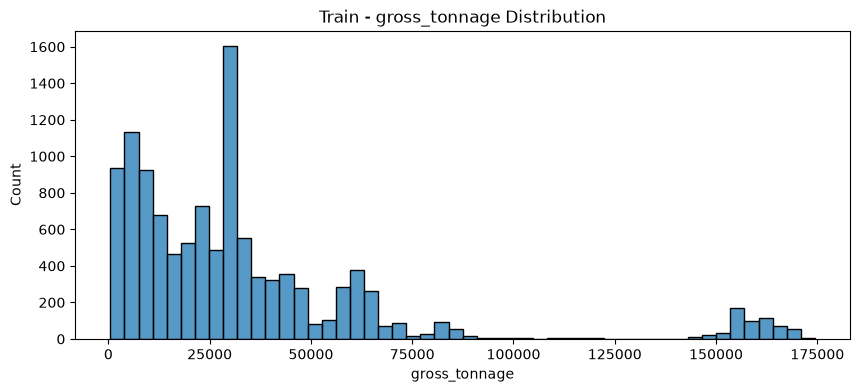

count     78381.000000
mean      20726.527156
std       34630.529159
min         100.000000
25%         749.000000
50%        4270.000000
75%       29152.000000
max      403342.000000
Name: gross_tonnage, dtype: float64

결측치 수: 214
0 이하 값 수: 0
무한대 값 수: 0


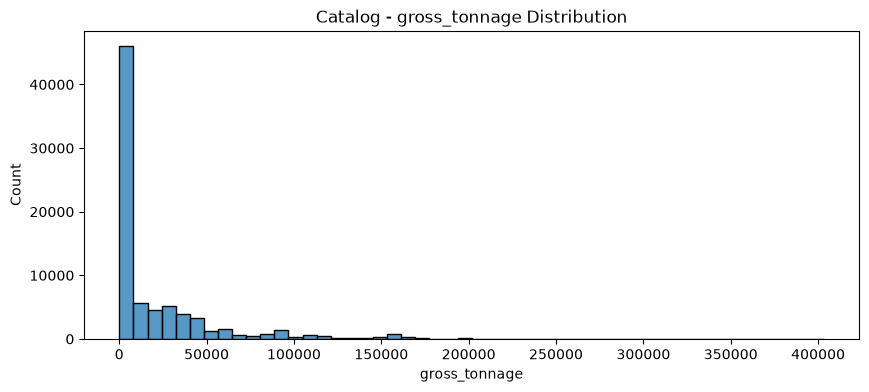

count     11429.000000
mean      33801.296089
std       35136.914366
min         522.000000
25%        9981.000000
50%       27658.000000
75%       41281.000000
max      174407.000000
Name: international_gross_tonnage, dtype: float64

결측치 수: 794
0 이하 값 수: 0
무한대 값 수: 0


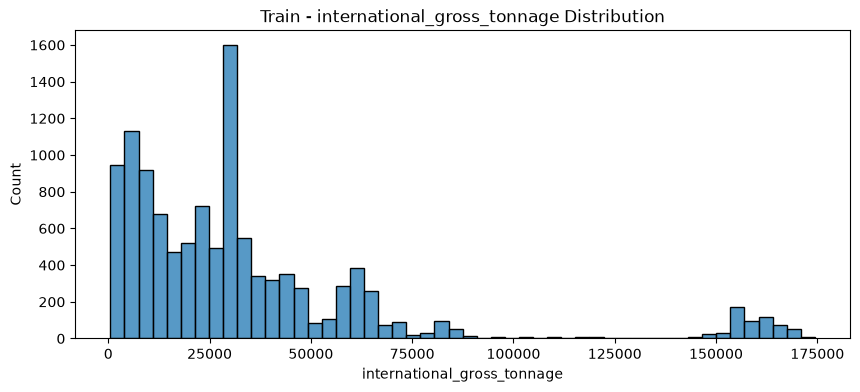

===== Train =====


vessel_type
석유제품 운반선       2918
일반화물선          2281
산물선(벌크선)       1835
케미칼 운반선        1468
원유운반선          1293
LPG 운반선         775
자동차운반선          768
풀컨테이너선          651
케미칼가스 운반선        77
LNG 운반선          53
기타 유조선           31
기타선              23
세미(혼재)컨테이너선      19
견인용예선            18
크루즈선              6
철강재 운반선           2
석탄운반선             2
냉동.냉장선            1
여객선               1
Name: count, dtype: int64

===== Catalog =====


vessel_type
Bulk             12128
GCargo           11973
Products          6919
Container         6705
Pass              4052
                 ...  
Rfr/Pass/RoRo        1
Pass/Tri             1
FPDSO                1
LPG/FPSO             1
LH2 Carrier          1
Name: count, Length: 138, dtype: int64

,target_vessel_id,vessel_name_train,vessel_type_train,vessel_id,vessel_name_catalog,vessel_type_catalog
0,VESSEL_00018,FEILCITY,원유운반선,VESSEL_00018,Felicity,Tanker
1,VESSEL_00018,FEILCITY,원유운반선,VESSEL_00018,Felicity,Tanker
2,VESSEL_00050,GRANDE RIVIERE,케미칼 운반선,VESSEL_00050,Grande Riviere,Methanol
3,VESSEL_17888,흥아영,풀컨테이너선,VESSEL_17888,Heung-A Young,Container
4,VESSEL_17888,흥아영,풀컨테이너선,VESSEL_17888,Heung-A Young,Container
5,VESSEL_17888,흥아영,풀컨테이너선,VESSEL_17888,Heung-A Young,Container
6,VESSEL_17888,흥아영,풀컨테이너선,VESSEL_17888,Heung-A Young,Container
7,VESSEL_00079,BELRGACE,산물선(벌크선),VESSEL_00079,Belgrace,Bulk
8,VESSEL_00082,ONIROI,석유제품 운반선,VESSEL_00082,Oneiroi,Products
9,VESSEL_00082,ONIROI,석유제품 운반선,VESSEL_00082,Oneiroi,Products


전체 선박 수: 5851
Train에서 선박 유형이 2개 이상인 선박 수: 195


... (2 outputs left out)


===== Train =====
국가명 종류: 76
결측치 수: 2016


flag_name
파나마          2349
NaN          2016
마샬 제도        1476
라이베리아        1130
싱가포르          875
             ... 
캐나다             1
카타르             1
세인트키츠 네비스       1
룩셈부르크           1
이란              1
Name: count, Length: 77, dtype: int64


===== Catalog =====
국가명 종류: 195
결측치 수: 0


flag_name
Peoples' Republic of China    8626
Panama                        7651
Liberia                       5373
Indonesia                     5151
Marshall Islands              3982
                              ... 
Slovenia                         1
Monaco                           1
Czech Republic                   1
Bosnia & Herzegovina             1
Reg. Especial Brasiliero         1
Name: count, Length: 195, dtype: int64

In [13]:
# vessel_name 정규화
# 1. 선박명 언어 유형 확인
name = train["vessel_name"].fillna("").astype(str)

has_korean = name.str.contains(r"[가-힣]", regex=True)
has_english = name.str.contains(r"[A-Za-z]", regex=True)

categories = pd.Series("기타", index=train.index)
categories.loc[has_korean & ~has_english] = "한글"
categories.loc[has_english & ~has_korean] = "영문"
categories.loc[has_korean & has_english] = "혼합"

summary = categories.value_counts().reindex(["한글", "영문", "혼합", "기타"], fill_value=0).to_frame("개수")

summary["비중(%)"] = (summary["개수"] / len(train) * 100).round(2)

display(summary)

# 혼합 선박명 실제 사례
display(train.loc[categories == "혼합", ["vessel_name"]].head(20))


# 2. 특수문자 종류 확인
# 한글·영문·숫자·공백을 제외한 문자 추출
special_chars = Counter(ch
for vessel_name in name
    for ch in vessel_name
    if not (
        re.fullmatch(r"[가-힣A-Za-z0-9\s]", ch)
    )
)

# -, . , /, Ⅱ, Ⅲ 존재하나 앞으로 들어올 test 데이터를 고려해서 패키지를 활용하면 더 유용할 것으로 보임
display(pd.DataFrame(special_chars.most_common(),columns=["특수문자", "등장 횟수"]))


# 3. vessel_name 정규화 함수 작성
def normalize_name(value):
    if not isinstance(value, str):
        return ""

    # 1) Unicode NFKC 정규화 (Ⅱ → II, Ⅲ → III)
    value = unicodedata.normalize("NFKC", value)

    # 2) 영문 대문자 통일
    value = value.upper()

    # 3) 공백 및 특수문자 제거 (한글·영문·숫자 유지)
    value = "".join(ch for ch in value if ch.isalnum())

    return value


# Train / Catalog에 동일한 정규화 적용
train["vessel_name_normalized"] = train["vessel_name"].apply(normalize_name)
catalog["catalog_name_normalized"] = catalog["vessel_name"].apply(normalize_name)

# gross tonnage / international gross tonnage 전처리
# 1. Gross Tonnage 분포 및 기술통계량 확인
def check_tonnage_distribution(df, name, col="gross_tonnage"):
    # 기술통계량
    display(df[col].describe())

    # 결측치 및 비정상값 확인
    numeric = pd.to_numeric(df[col], errors="coerce")

    print("결측치 수:", numeric.isna().sum())
    print("0 이하 값 수:", (numeric <= 0).sum())
    print("무한대 값 수:", np.isinf(numeric).sum())

    # 히스토그램
    plt.figure(figsize=(10, 4))
    sns.histplot(numeric.replace([np.inf, -np.inf], np.nan).dropna(),
                 bins=50)

    plt.title(f"{name} - {col} Distribution")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()


# 2. 톤수 전처리 함수
def positive_float(value):
    try:
        number = float(value)
    except (TypeError, ValueError):
        return np.nan

    # 유한한 양수만 유지
    return number if np.isfinite(number) and number > 0 else np.nan


# 3. 전처리 전 분포 확인
check_tonnage_distribution(train, "Train")
check_tonnage_distribution(catalog, "Catalog")

# 국제총톤수도 별도 확인
check_tonnage_distribution(train, "Train", "international_gross_tonnage")


# 4. Train / Catalog 전처리 적용
train["gross_tonnage_clean"] = (
    train["gross_tonnage"].apply(positive_float)
)

catalog["gross_tonnage_clean"] = (
    catalog["gross_tonnage"].apply(positive_float)
)

train["international_gross_tonnage_clean"] = (
    train["international_gross_tonnage"].apply(positive_float)
)

# vessel_type 전처리

# 1. Train / Catalog의 vessel_type 종류 및 빈도 확인
print("===== Train =====")
display(train["vessel_type"].value_counts())

print("===== Catalog =====")
display(catalog["vessel_type"].value_counts())


# 2. 동일 선박 ID 기준으로 vessel_name과 vessel_type 비교
type_compare = train[
    ["target_vessel_id", "vessel_name", "vessel_type"]
].merge(
    catalog[["vessel_id", "vessel_name", "vessel_type"]],
    left_on="target_vessel_id",
    right_on="vessel_id",
    how="left",
    suffixes=("_train", "_catalog"),
    validate="many_to_one"
)

# 개별 선박 비교 결과
display(type_compare.head(20))


# 3. vessel_id별 Train / Catalog 선박 유형 비교
type_by_vessel = (
    type_compare
    .groupby(["target_vessel_id", "vessel_name_catalog", "vessel_type_catalog"])
    .agg(
        train_names=("vessel_name_train", lambda x: list(x.unique())),
        train_types=("vessel_type_train", lambda x: list(x.unique())),
        train_type_count=("vessel_type_train", "nunique"),
        record_count=("vessel_type_train", "size")
    )
    .reset_index()
)

# 4. 동일 vessel_id에서 여러 유형이 나타나는 선박 확인
type_conflicts = type_by_vessel[
    type_by_vessel["train_type_count"] > 1
]

print("전체 선박 수:", len(type_by_vessel))
print("Train에서 선박 유형이 2개 이상인 선박 수:", len(type_conflicts))

display(type_by_vessel.head(20))
display(type_conflicts.head(20))

# flag_name 전처리
# 1. Train / Catalog의 국가명 종류 및 빈도 확인

for name, df in [("Train", train), ("Catalog", catalog)]:
    print(f"\n===== {name} =====")
    print("국가명 종류:", df["flag_name"].nunique())
    print("결측치 수:", df["flag_name"].isna().sum())

    display(df["flag_name"].value_counts(dropna=False))

## **EDA**

| 구분 | Levenshtein (레벤슈타인) | Jaro-Winkler (자로-윙클러) | RapidFuzz (래피드퍼즈) |
|---|---|---|---|
| **핵심 개념** | 두 문자열을 같게 만들기 위해 몇 글자를 수정해야 하는지 계산 | 글자의 위치와 앞부분이 얼마나 비슷한지 계산 | 여러 문자열 유사도 알고리즘을 제공하는 라이브러리 |
| **비교 방식** | 글자 추가·삭제·변경 횟수 계산 | 글자 일치 여부·순서·앞부분 일치 정도 계산 | 선택한 함수에 따라 오탈자, 단어 순서 등을 비교 |
| **잘 찾는 경우** | 글자 누락, 추가, 오타 | 글자 순서 뒤바뀜, 앞부분 유사 | 단어 순서 변경, 다양한 표기 차이 |
| **영문 예시** | SHIP ↔ SHIIP | MARHTA ↔ MARTHA | BLUE OCEAN ↔ OCEAN BLUE |
| **한글 예시** | 청해진 ↔ 청해진호 | 대한선박 ↔ 대한선박호 | 푸른 바다 ↔ 바다 푸른 |
| **한글 ↔ 한글** | 가능 | 가능 | 가능 |
| **영문 ↔ 영문** | 가능 | 가능 | 가능 |
| **한글 ↔ 영문** | 계산 가능하지만 효과 낮음 | 계산 가능하지만 효과 낮음 | 문자 기반 함수만으로는 효과 낮음 |
| **주요 한계** | 단어 순서 변경에 취약 | 앞부분이 비슷한 다른 이름에도 높은 점수가 나올 수 있음 | 함수 선택에 따라 결과가 달라짐 |

In [14]:

# vessel_name에 관련해서 불일치 유형 분석
# vessel_name이 중복된 행 확인 >> 즉, train 내부에도 중복은 되었지만 vessel_name이 다른 경우가 있음
duplicate_names = train[train.duplicated("vessel_name", keep=False)].sort_values("vessel_name")

print("중복된 선박명 종류:", duplicate_names["vessel_name"].nunique())
print("중복된 행 수:", len(duplicate_names))

display(duplicate_names[
    ["vessel_name", "target_vessel_id", "sample_id"]
].head(30))

중복된 선박명 종류: 2678
중복된 행 수: 9043


,vessel_name,target_vessel_id,sample_id
12187,109효동케미,VESSEL_64418,TRAIN_06849
12188,109효동케미,VESSEL_64418,TRAIN_08183
12189,109효동케미,VESSEL_64418,TRAIN_09201
12190,109효동케미,VESSEL_64418,TRAIN_09502
10568,21 SUNNY,VESSEL_68082,TRAIN_01519
10569,21 SUNNY,VESSEL_68082,TRAIN_04356
12169,303효동케미,VESSEL_05417,TRAIN_05982
12170,303효동케미,VESSEL_05417,TRAIN_06334
12171,303효동케미,VESSEL_05417,TRAIN_06887
12172,303효동케미,VESSEL_05417,TRAIN_08009


**정규화 후 오류 유형별 분포**

| 유형          | 건수     | 비율    | 실제 예시 (Train → Catalog)              |
| ----------- | ------ | ----- | ------------------------------------ |
| 정상 일치       | 7,137  | 58.4% | `SFLPUMA` → `SFLPUMA`                |
| 문자 1개 차이    | 2,488  | 20.4% | `MONINGCAPO` → `MORNINGCAPO`         |
| 문자 2개 차이    | 1,315  | 10.8% | `JUMBOVISOIN` → `JUMBOVISION`        |
| 문자 3개 차이    | 79     | 0.6%  | `STENAIMPESSOIN` → `STENAIMPRESSION` |
| 문자 4개 이상 차이 | 12     | 0.1%  | `BOWMERCURY` → `BENTENGALAXY`        |
| 한글 ↔ 영문     | 1,191  | 9.7%  | `모닝쿠리어` → `MORNINGCOURIER`           |
| 전체          | 12,222 | 100%  |                                      |

**정규화 후 오류 유형 종류**
| 오류 유형 | 실제 사례 (Train → Catalog) | 해결 방향 |
|---|---|---|
| 문자 삽입 | `GRANDVICCTORY` → `GRANDVICTORY` | 편집거리 |
| 문자 누락 | `MONINGCAPO` → `MORNINGCAPO` | 편집거리 |
| 문자 치환 | `KITIRA` → `KITHIRA` | 편집거리 |
| 문자 위치 변경 | `JUMBOVISOIN` → `JUMBOVISION` | Damerau-Levenshtein |
| 복합 오탈자 | `TORMADVENUTRER` → `TORMADVENTURER` | Fuzzy / ByT5 |
| 한글 음역 | `모닝쿠리어` → `MORNINGCOURIER` | 한영 음역 매칭 |
| 한글 숫자 표현 | `제7하나` → `NO7HANA` | 숫자·접두어 규칙 |
| 선박명 상이 | `BOWMERCURY` → `BENTENGALAXY` | 다른 속성 활용 |

전체 데이터: 12223
Catalog 매칭 실패: 1


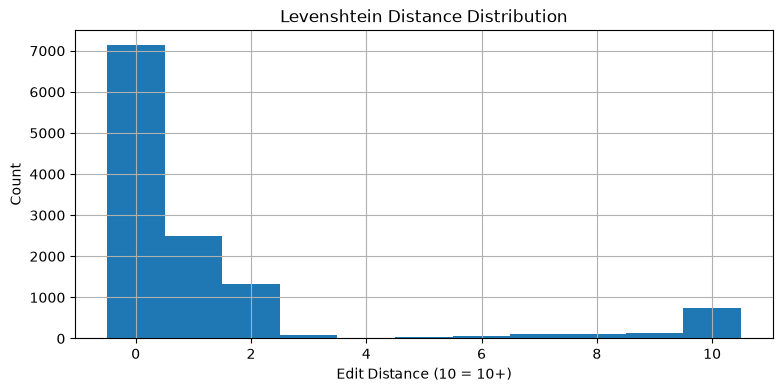

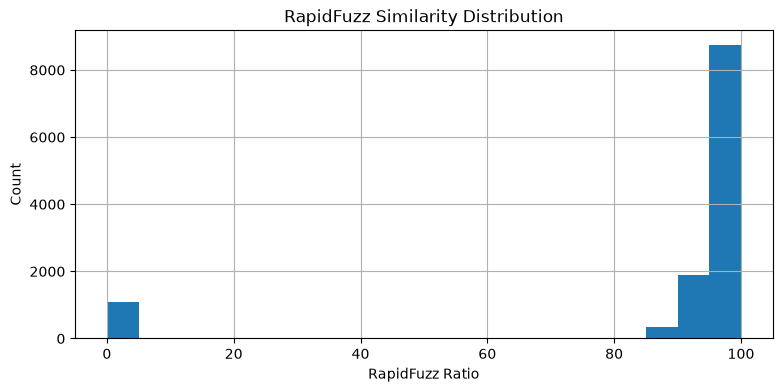

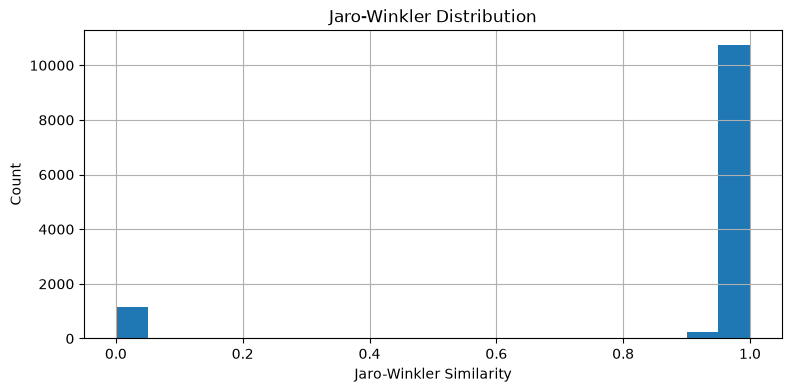

,건수,비율(%)
edit_group,,
0,7137,58.39
1,2488,20.36
2,1315,10.76
3,84,0.69
4~5,37,0.30
6+,1161,9.50


,건수,비율(%)
jaro_winkler_group,,
낮음,1202,9.83
보통,2,0.02
높음,25,0.20
매우 높음,10993,89.94


,건수,비율(%)
fuzz_group,,
0~50,1198,9.80
50~70,5,0.04
70~80,2,0.02
80~90,514,4.21
90~<100,3366,27.54
100,7137,58.39


,vessel_name_normalized,catalog_name_normalized
3,흥아영,HEUNGAYOUNG
4,흥아영,HEUNGAYOUNG
5,흥아영,HEUNGAYOUNG
6,흥아영,HEUNGAYOUNG
73,흥아하이퐁,HEUNGAHAIPHONG
...,...,...
12172,303효동케미,303HYODONGCHEMI
12187,109효동케미,109HYODONGCHEMI
12188,109효동케미,109HYODONGCHEMI
12189,109효동케미,109HYODONGCHEMI


,vessel_name_normalized,catalog_name_normalized
3,흥아영,HEUNGAYOUNG
4,흥아영,HEUNGAYOUNG
5,흥아영,HEUNGAYOUNG
6,흥아영,HEUNGAYOUNG
73,흥아하이퐁,HEUNGAHAIPHONG
...,...,...
12172,303효동케미,303HYODONGCHEMI
12187,109효동케미,109HYODONGCHEMI
12188,109효동케미,109HYODONGCHEMI
12189,109효동케미,109HYODONGCHEMI


,vessel_name_normalized,catalog_name_normalized
3,흥아영,HEUNGAYOUNG
4,흥아영,HEUNGAYOUNG
5,흥아영,HEUNGAYOUNG
6,흥아영,HEUNGAYOUNG
73,흥아하이퐁,HEUNGAHAIPHONG
...,...,...
12172,303효동케미,303HYODONGCHEMI
12187,109효동케미,109HYODONGCHEMI
12188,109효동케미,109HYODONGCHEMI
12189,109효동케미,109HYODONGCHEMI


In [15]:

# 정답 선박명 연결 catalog - train
df = train.merge(
    catalog[["vessel_id", "catalog_name_normalized"]],
    left_on="target_vessel_id",
    right_on="vessel_id",
    how="left",
    validate="many_to_one"
)

# 정답 매칭 확인
print("전체 데이터:", len(df))
print("Catalog 매칭 실패:", df["catalog_name_normalized"].isna().sum())

# 결측치가 없는 데이터만 비교
valid = df.dropna(subset=["vessel_name_normalized","catalog_name_normalized"]).copy()

a = valid["vessel_name_normalized"].astype(str)
b = valid["catalog_name_normalized"].astype(str)

pairs = list(zip(a, b))

# 1. 편집거리 : 두 문자열을 같게 만들기 위한 최소 삽입, 삭제, 치환 횟수
valid["edit_distance"] = [distance.Levenshtein.distance(x, y)for x, y in pairs]

# 2. RapidFuzz Ratio (0~100) >> 문자열 유사도를 표시
valid["fuzz_ratio"] = [fuzz.ratio(x, y)for x, y in pairs]

# 3. Jaro-Winkler (0~1) >> 두 문자열에서 일치하는 문자 수와 문자 순서가 얼마나 비슷한지 계산 + 문자 앞부분 위치
valid["jaro_winkler"] = [distance.JaroWinkler.similarity(x, y)for x, y in pairs]

# 4. 문자열 길이 차이
valid["length_diff"] = [abs(len(x) - len(y))for x, y in pairs]

# 전체 분포 확인
valid["edit_distance"].value_counts().sort_index()

plt.figure(figsize=(9, 4))

valid["edit_distance"].clip(upper=10).hist(bins=np.arange(-0.5, 11.5, 1))

plt.xlabel("Edit Distance (10 = 10+)")
plt.ylabel("Count")
plt.title("Levenshtein Distance Distribution")
plt.show()


plt.figure(figsize=(9, 4))
valid["fuzz_ratio"].hist(bins=20)
plt.xlabel("RapidFuzz Ratio")
plt.ylabel("Count")
plt.title("RapidFuzz Similarity Distribution")
plt.show()

plt.figure(figsize=(9, 4))
valid["jaro_winkler"].hist(bins=20)
plt.xlabel("Jaro-Winkler Similarity")
plt.ylabel("Count")
plt.title("Jaro-Winkler Distribution")
plt.show()

# 편집거리 구간
valid["edit_group"] = pd.cut(valid["edit_distance"],bins=[-1, 0, 1, 2, 3, 5, float("inf")],labels=["0", "1", "2", "3", "4~5", "6+"])

# Jaro Winkler
valid["jaro_winkler_group"] = pd.cut(valid["jaro_winkler"], bins=[0, 0.7, 0.8, 0.9, 1.0], labels=["낮음", "보통", "높음", "매우 높음"], include_lowest=True)

# RapidFuzz 구간 >> 전체 문자열 유사도
valid["fuzz_group"] = pd.cut(valid["fuzz_ratio"],bins=[-0.1, 50, 70, 80, 90, 99.999, 100],labels=["0~50", "50~70", "70~80","80~90", "90~<100", "100"])

def distribution_table(series):
    counts = series.value_counts(sort=False)
    return pd.DataFrame({
        "건수": counts,
        "비율(%)": (counts / len(series) * 100).round(2)
    })

display(distribution_table(valid["edit_group"]))
display(distribution_table(valid["jaro_winkler_group"]))
display(distribution_table(valid["fuzz_group"]))

# 편집구간 데이터 확인
## 비한글 음역대 문제
display(valid[valid["edit_group"].isin(["4~5", "6+"])][["vessel_name_normalized","catalog_name_normalized"]])

# Jaro-Winkler 취약 구간 (0.8 이하)
display(valid[valid["jaro_winkler_group"].isin(["낮음"])][["vessel_name_normalized","catalog_name_normalized"]])

# RapidFuzz 취약 구간 (80 이하)
display(valid[valid["fuzz_group"].isin(["0~50"]) ][["vessel_name_normalized","catalog_name_normalized"]])

## **Train/Test 나누기**

In [16]:
# Train과 Catalog 연결
df = train.merge(
    catalog[["vessel_id", "catalog_name_normalized"]],
    left_on="target_vessel_id",
    right_on="vessel_id",
    how="left",
    validate="many_to_one"
)

# Catalog에 정답이 없는 행 제거
before = len(df)

df = df.dropna(
    subset=["catalog_name_normalized"]
).copy().reset_index(drop=True)

print(f"Catalog 미매칭으로 제외: {before - len(df):,}건")

# 학습에 필요한 컬럼과 정답 연결 상태 확인
required_cols = [
    "vessel_name_normalized",
    "catalog_name_normalized",
    "target_vessel_id"
]

assert set(required_cols).issubset(df.columns), "필요한 컬럼을 확인하세요."
assert df[required_cols].notna().all().all(), "입력 또는 정답에 결측치가 있습니다."
assert df[required_cols].ne("").all().all(), "입력 또는 정답에 빈 문자열이 있습니다."

# 같은 선박 ID는 같은 쪽에 배정
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(df, groups=df["target_vessel_id"])
)

# 정규화 컬럼과 보조 정보를 모두 유지
train_df = df.iloc[train_idx].copy().reset_index(drop=True)
val_df = df.iloc[val_idx].copy().reset_index(drop=True)

# 선박 ID 중복 확인
train_ids = set(train_df["target_vessel_id"])
val_ids = set(val_df["target_vessel_id"])

assert train_ids.isdisjoint(val_ids), \
    "학습·검증에 같은 선박이 포함되어 있습니다."

print(f"학습: {len(train_df):,}행 / 선박 {len(train_ids):,}개")
print(f"검증: {len(val_df):,}행 / 선박 {len(val_ids):,}개")
print("학습·검증 간 중복 선박: 0개")

Catalog 미매칭으로 제외: 1건
학습: 9,878행 / 선박 4,680개
검증: 2,344행 / 선박 1,171개
학습·검증 간 중복 선박: 0개


## **Call Sign History — 학습용 / 검증용 / 최종 Test용 구분**

- **내부 Train**: 자신의 `sample_id` 행을 제외한 Train History를 조회 (동일 Call Sign의 다른 학습 행 허용)
- **내부 Validation**: 내부 `train_df`의 History만 조회. `val_df` 정답은 History에 절대 추가하지 않음
- **최종 Test**: 대회 제공 `train.csv` 전체 (내부 Train+Validation) History 사용


In [17]:
# call sign history 불러오기
def build_call_sign_history(source):
    hist=source[['sample_id','call_sign_normalized','target_vessel_id','vessel_name']].copy()
    hist=hist.dropna(subset=['target_vessel_id'])
    hist=hist[hist['call_sign_normalized'].ne('')]
    hist['target_vessel_id']=hist['target_vessel_id'].astype(str)
    hist['name_norm']=hist['vessel_name'].map(normalize_name)
    return ({cs:g.to_dict('records') for cs,g in hist.groupby('call_sign_normalized')},
            {vid:g.to_dict('records') for vid,g in hist.groupby('target_vessel_id')})

TRAIN_CALL_HISTORY, TRAIN_VESSEL_HISTORY = build_call_sign_history(train_df)
FULL_CALL_HISTORY, FULL_VESSEL_HISTORY = build_call_sign_history(train)
# 재사용 가능하도록 전체 제공 Train History 저장 (최종 Test에서 복원 가능)
HISTORY_EXPORT_PATH = EXPERIMENT_DIR / 'call_sign_history_full_train.csv'
train[['sample_id','call_sign_normalized','target_vessel_id','vessel_name','arrival_year']].to_csv(HISTORY_EXPORT_PATH,index=False,encoding='utf-8-sig')
print('Train Call Sign History:',len(TRAIN_CALL_HISTORY), '| Test용 전체 History:',len(FULL_CALL_HISTORY))
print('전체 History 저장 경로:',HISTORY_EXPORT_PATH)



# 한글,비한글 비중 확인
for name, part in [("학습", train_df), ("검증", val_df)]:
    korean = part["vessel_name"].str.contains(r"[가-힣]", na=False)
    print(f"{name}: 한글 {korean.sum():,}행 / 비한글 {(~korean).sum():,}행")

Train Call Sign History: 4680 | Test용 전체 History: 5851
전체 History 저장 경로: /workspace/open/vessel_matching_gbdt_byt5/retrieval_cache/tfidf1000_nonko_train_check/call_sign_history_full_train.csv
학습: 한글 948행 / 비한글 8,930행
검증: 한글 243행 / 비한글 2,101행


## **Retrieval**
- 비한글 TF-IDF Top 1,000 / 한글 자모 TF-IDF Top 1000 → 기존 RRF Top 100
- Call Sign이 같은 History 내역 후보 보존

In [18]:
# 추론 시간 계산
prep_start = time.perf_counter()
cat = catalog.reset_index(drop=True).copy()
cat_names = cat['catalog_name_normalized'].fillna('').astype(str).tolist()
cat_ids = cat['vessel_id'].astype(str).to_numpy()
CATALOG_ID_TO_ROW = {v:i for i,v in enumerate(cat_ids)}

assert len(cat_ids) == len(set(cat_ids))
cat_ton = pd.to_numeric(cat['gross_tonnage'], errors='coerce').to_numpy(dtype=float)
_cat_flag_ok = cat['flag_name'].notna().to_numpy()
_cat_type_ok = cat['vessel_type'].notna().to_numpy()
model_bge = BGEM3FlagModel(BGE_MODEL_ID, use_fp16=torch.cuda.is_available())

# 해쉬 번호 남기기
def fingerprint(values):
    payload = json.dumps(values, ensure_ascii=False, separators=(',', ':')).encode('utf-8')
    return hashlib.sha256(payload).hexdigest()

# 텍스트를 입력받아서 embedding
def encode_queries(values, cache):
    vals = [str(v).strip() if pd.notna(v) else '' for v in values]
    missing = list(dict.fromkeys(x for x in vals if x not in cache))
    if missing:
        vec = model_bge.encode(missing, batch_size=BGE_BATCH_SIZE, max_length=128, return_dense=True, return_sparse=False, return_colbert_vecs=False)['dense_vecs']
        vec = normalize(np.asarray(vec, dtype=np.float32), norm='l2')
        cache.update(zip(missing, vec))
    return np.ascontiguousarray(np.stack([cache[x] for x in vals]), dtype=np.float32)

# catalog 미리 한번에 embedding >> TF-iDF 및 후보 검색 시 사용
def catalog_embeddings(values, field):
    vals = [str(v).strip() if pd.notna(v) else '' for v in values]
    signature = fingerprint([BGE_MODEL_ID, 128, bool(torch.cuda.is_available()), vals])
    path = EXPERIMENT_DIR / f'bge_{field}_{signature[:16]}.npz'
    unique, inverse = np.unique(np.asarray(vals, dtype=str), return_inverse=True)
    if path.exists():
        with np.load(path, allow_pickle=False) as saved:
            vec = saved['vectors']
        assert vec.shape[0] == len(unique) and np.isfinite(vec).all()
    else:
        vec = encode_queries(unique.tolist(), {})
        np.savez_compressed(path, vectors=vec)
    return np.ascontiguousarray(vec[inverse]), dict(zip(unique.tolist(), vec))

cat_name_vec, name_cache = catalog_embeddings(cat_names, 'name')
attr_vec, attr_cache = {}, {}
for field in ['flag_name', 'vessel_type']:
    attr_vec[field], attr_cache[field] = catalog_embeddings(cat[field].tolist(), field)
embedding_prep_seconds = time.perf_counter() - prep_start
print(f'모델·카탈로그 임베딩 준비: {embedding_prep_seconds:.2f}초 (검색 시간과 별도)')

# rrf 순위 정렬
def rrf_rank(frame, name_cols, aux_weight=DEFAULT_AUX_WEIGHT, top_k=TOP_K):
    weights = {col: NAME_WEIGHT for col in name_cols}
    weights.update({
        'flag_cosine': aux_weight,
        'type_cosine': aux_weight,
        'tonnage_similarity': aux_weight
    })

    n = len(frame)
    score = np.zeros(n, dtype=np.float64)

    for col, weight in weights.items():
        values = frame[col].to_numpy(dtype=np.float64)
        valid_idx = np.flatnonzero(~np.isnan(values))
        if valid_idx.size == 0:
            continue

        # 내림차순 정렬하고 동점에는 동일한 최소 순위 부여
        order = np.argsort(-values[valid_idx], kind='stable')
        sorted_values = values[valid_idx][order]
        starts = np.r_[True, sorted_values[1:] != sorted_values[:-1]]
        ranks = np.maximum.accumulate(
            np.where(starts, np.arange(1, len(order) + 1), 0)
        )

        score[valid_idx[order]] += weight / (RRF_K + ranks)

    # rrf rank 유지
    primary = frame['name_primary'].to_numpy(dtype=np.float64)
    primary = np.nan_to_num(primary, nan=-np.inf)
    order = np.lexsort((np.arange(n), -primary, -score))[:top_k]

    result = frame.iloc[order].copy().reset_index(drop=True)
    result['rrf_score'] = score[order]
    return result

tokenizer_config.json:   0%|          | 0.00/444 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

.gitattributes: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

... (20 outputs left out)

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

sparse_linear.pt:   0%|          | 0.00/3.52k [00:00<?, ?B/s]

pre tokenize: 100%|██████████| 2447/2447 [00:01<00:00, 1889.62it/s]
You're using a XLMRobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
Inference Embeddings: 100%|██████████| 5/5 [00:00<00:00, 80.37it/s]

모델·카탈로그 임베딩 준비: 68.37초 (검색 시간과 별도)


### **카탈로그 음역 캐시**

다음 셀은 캐시에 없는 음역만 생성

In [19]:
# Hugging Face 영→한 음역 모델 및 JSON 저장
# mT5 기반 음역 모델 직접 로드

TRANSLIT_MODEL = 'eunsour/en-ko-transliterator'
TRANSLIT_JSON = EXPERIMENT_DIR / 'catalog_enko_transliteration_mt5.json'

# 기존 음역 JSON이 있으면 불러오고 없으면 새로 생성 >> 📍 실제 대회 파일 내부에 첨부
translit_cache = json.loads(TRANSLIT_JSON.read_text(encoding='utf-8')) if TRANSLIT_JSON.exists() else {'model': TRANSLIT_MODEL, 'word_cache': {}, 'name_cache': {}}

if translit_cache.get('model') != TRANSLIT_MODEL:
    raise ValueError('음역 JSON의 모델과 현재 모델이 다릅니다.')

word_cache = translit_cache.setdefault('word_cache', {})
name_cache_ko = translit_cache.setdefault('name_cache', {})

# 영문 선박명을 공백·숫자 기준 단어로 분리
def catalog_words(raw): return re.findall(r'[A-Za-z]+|[0-9]+|[가-힣]+', str(raw))
catalog_original_names = cat['vessel_name'].fillna('').astype(str).tolist()

# 음역 대상 단어 추출 및 기존 JSON 확인
unique_words = list(dict.fromkeys(w for name in catalog_original_names for w in catalog_words(name) if re.search(r'[A-Za-z]', w)))

# 이미 음역한 단어를 제외하여 재계산 방지
missing_words = [w for w in unique_words if w not in word_cache]

# 미변환 단어만 Hugging Face 모델로 음역
if missing_words:

    # Hugging Face 영문→한글 음역 모델 준비
    translit_model = AutoModelForSeq2SeqLM.from_pretrained(TRANSLIT_MODEL).to(DEVICE).eval()
    translit_tokenizer = AutoTokenizer.from_pretrained(TRANSLIT_MODEL)

    # 단어 배치별 모델 추론
    for start in tqdm(range(0, len(missing_words), 16), desc='Hugging Face 단어별 음역'):
        words = missing_words[start:start+16]
        inputs = translit_tokenizer(words, padding=True, truncation=True, max_length=64, return_tensors='pt').to(DEVICE)

        with torch.inference_mode():
            outputs = translit_model.generate(**inputs, max_new_tokens=64, num_beams=1, do_sample=False)

        # 모델의 생성 토큰을 한글 단어로 복원
        converted = translit_tokenizer.batch_decode(outputs, skip_special_tokens=True)
        word_cache.update(zip(words, [v.strip() for v in converted]))

        if start % 1600 == 0:
            TRANSLIT_JSON.write_text(json.dumps(translit_cache, ensure_ascii=False), encoding='utf-8')

    del translit_model, translit_tokenizer
    gc.collect()
    if DEVICE == 'cuda': torch.cuda.empty_cache()

# 단어별 음역 결과 결합 및 JSON 저장

# 단어별 결과를 결합하여 Catalog 선박명 전체 변환
cat_translit_ko = []
for raw in catalog_original_names:
    words = catalog_words(raw)
    converted = [word_cache[w] if w in word_cache else w for w in words]
    joined = re.sub(r'\s+', '', ''.join(converted))
    name_cache_ko[raw] = {'words': words, 'transliterated': converted, 'joined': joined}
    cat_translit_ko.append(joined)

# 변환 결과를 JSON 파일로 최종 저장
TRANSLIT_JSON.write_text(json.dumps(translit_cache, ensure_ascii=False, indent=2), encoding='utf-8')
print('음역 JSON:', TRANSLIT_JSON, '단어:', len(word_cache), '선박명:', len(name_cache_ko))
print('음역 예시:', list(zip(catalog_original_names[:5], cat_translit_ko[:5])))

# 제출/실전 공통: 미리 생성한 음역 JSON만 로드 (음역 모델 다운로드·추론 금지)
if not TRANSLIT_JSON.is_file():
    raise FileNotFoundError(f"음역 JSON이 없습니다: {TRANSLIT_JSON}. 실험 전처리에서 한 번 생성하세요.")

translit_cache = json.loads(TRANSLIT_JSON.read_text(encoding='utf-8'))

if translit_cache.get('model') != TRANSLIT_MODEL:
    raise ValueError('음역 JSON의 모델과 현재 모델이 다릅니다.')

word_cache = translit_cache.get('word_cache', {})
name_cache_ko = translit_cache.get('name_cache', {})
catalog_original_names = cat['vessel_name'].fillna('').astype(str).tolist()
missing_names = [raw for raw in set(catalog_original_names) if raw not in name_cache_ko]

if missing_names:
    raise ValueError(f"음역 JSON에 catalog 선박명 {len(missing_names):,}개가 누락됐습니다. 예: {missing_names[:5]}")

cat_translit_ko = [name_cache_ko[raw]['joined'] for raw in catalog_original_names]
print(f"음역 JSON 로드 완료: {TRANSLIT_JSON} | 선박명 {len(cat_translit_ko):,}개 | 새 음역 추론 0건")

config.json:   0%|          | 0.00/744 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.33G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/450 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565
/usr/local/lib/python3.12/dist-packages/transformers/convert_slow_tokenizer.py:561: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


Hugging Face 단어별 음역:   0%|          | 0/2157 [00:00<?, ?it/s]

음역 JSON: /workspace/open/vessel_matching_gbdt_byt5/retrieval_cache/tfidf1000_nonko_train_check/catalog_enko_transliteration_mt5.json 단어: 34504 선박명: 78594
음역 예시: [('SA Europe', '에스에이유럽'), ('SA Oceania', '에스에이오세아니아'), ('West Loyalty', '웨스트릴리티'), ('Al Siddeeq', '앨시디크'), ('South Loyalty', '사우스릴리티')]
음역 JSON 로드 완료: /workspace/open/vessel_matching_gbdt_byt5/retrieval_cache/tfidf1000_nonko_train_check/catalog_enko_transliteration_mt5.json | 선박명 78,595개 | 새 음역 추론 0건


In [20]:
# mT5 영→한 음역 모델 간단 테스트
TEST_MODEL = 'eunsour/en-ko-transliterator'

sample_words = [
    'Incheon', 'Infinity', 'Tao', 'Mariner',
    'Morning', 'Star', 'Golden', 'Hachi',
    'Asian', 'Captain'
]

# 모델 로드
tokenizer = AutoTokenizer.from_pretrained(TEST_MODEL)
model = AutoModelForSeq2SeqLM.from_pretrained(TEST_MODEL).to(DEVICE).eval()

# 샘플 음역
inputs = tokenizer(
    sample_words, padding=True, truncation=True,
    max_length=64, return_tensors='pt'
).to(DEVICE)

with torch.inference_mode():
    outputs = model.generate(
        **inputs, max_new_tokens=64,
        num_beams=1, do_sample=False
    )

# 결과 확인
results = tokenizer.batch_decode(outputs, skip_special_tokens=True)

display(pd.DataFrame({
    '영문': sample_words,
    '한글 음역 결과': results
}))

# GPU 메모리 정리
del model, tokenizer, inputs, outputs
gc.collect()
if DEVICE == 'cuda':
    torch.cuda.empty_cache()

/usr/local/lib/python3.12/dist-packages/transformers/convert_slow_tokenizer.py:561: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


,영문,한글 음역 결과
0,Incheon,인천
1,Infinity,인디니어
2,Tao,타우
3,Mariner,머린어
4,Morning,모닝
5,Star,스타
6,Golden,골든
7,Hachi,하치
8,Asian,아시안
9,Captain,캡틴


### **문자·자모 TF-IDF 인덱스**

In [21]:
# 문자, 자모 tf-idf 적용
tfidf_start = time.perf_counter()
def to_jamo(text):
    return j2hcj(h2j(str(text)))

def load_tfidf(texts, label):
    signature = fingerprint([cat_ids.tolist(), texts, 'char', [2, 4], 'l2'])
    path = EXPERIMENT_DIR / f'tfidf_{label}_{signature[:16]}.joblib'
    if path.exists():
        vectorizer, matrix = joblib.load(path)
    else:
        vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(2, 4), dtype=np.float32)
        matrix = vectorizer.fit_transform(texts)
        joblib.dump((vectorizer, matrix), path)
    assert matrix.shape[0] == len(cat)
    return vectorizer, matrix

name_tfidf_vectorizer, cat_name_tfidf = load_tfidf(cat_names, 'name')
cat_jamo = [to_jamo(normalize_name(x)) for x in cat_translit_ko]
jamo_vectorizer, cat_jamo_sparse = load_tfidf(cat_jamo, 'jamo')
print(f'TF-IDF 준비: {time.perf_counter() - tfidf_start:.2f}초')

def tfidf_topk(text, vectorizer, matrix, k=CHANNEL_K):
    row = (vectorizer.transform([text]) @ matrix.T).tocsr()
    row.eliminate_zeros()
    k = min(k, matrix.shape[0])
    ids, scores = row.indices, row.data

    # 경계 동점은 카탈로그 행 번호로 결정하여 실행마다 후보가 바뀌지 않게 함
    if len(ids) > k:
        cutoff = np.partition(scores, len(scores) - k)[len(scores) - k]
        higher = np.flatnonzero(scores > cutoff)
        equal = np.flatnonzero(scores == cutoff)
        equal = equal[np.argsort(ids[equal])[:k - len(higher)]]
        take = np.r_[higher, equal]
        ids, scores = ids[take], scores[take]
    order = np.lexsort((ids, -scores))
    ids, scores = ids[order], scores[order]
    positive_count = len(ids)
    # 공통 조각이 부족하면 유사도 0 동점 후보를 행 번호순으로 채움. 회수율 평가에서 숨기지 않음
    if len(ids) < k:
        extra = np.setdiff1d(np.arange(matrix.shape[0]), ids, assume_unique=True)[:k - len(ids)]
        ids, scores = np.r_[ids, extra], np.r_[scores, np.zeros(len(extra), dtype=np.float32)]
    return ids.astype(np.intp), scores, positive_count

TF-IDF 준비: 4.94초


### **공통 검색 및 언어별 특징 계산**

**전반적인 로직**
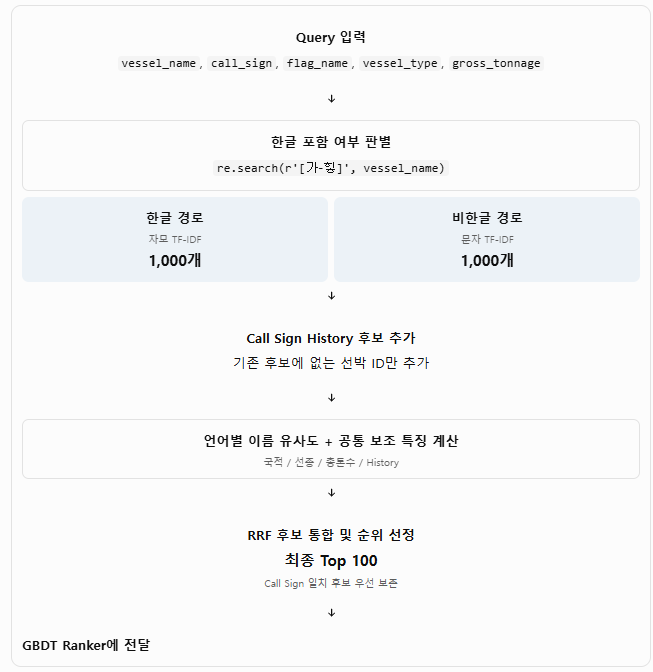

**비한글 로직**

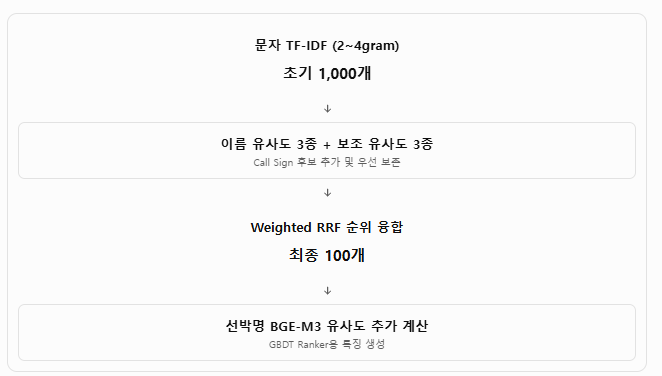



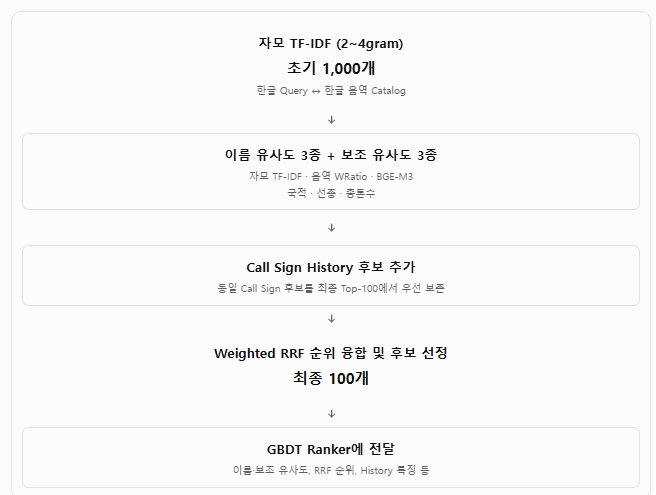

**한글 로직**
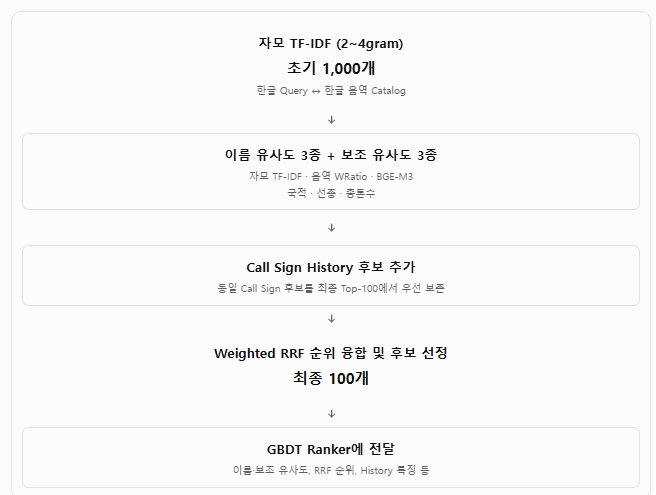

In [22]:
def sync_gpu():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

def timed_start():
    sync_gpu()
    return time.perf_counter()

def elapsed(start):
    sync_gpu()
    return time.perf_counter() - start

# 동일 검색 입력은 한 번 계산하고 원래 Query 행으로 복원. 정답은 검색에 사용하지 않음
def build_retrieval_pool(query_df, show_progress=True, history_mode='validation'):
    started = timed_start()
    q = query_df.reset_index(drop=True).copy()
    if q.empty:
        raise ValueError('검색 입력이 비어 있습니다.')
    q['vessel_name_normalized'] = q['vessel_name'].apply(normalize_name)
    q['call_sign_normalized'] = q['call_sign'].map(normalize_call_sign) if 'call_sign' in q else ''
    if 'sample_id' not in q: q['sample_id'] = ['__test_'+str(i) for i in range(len(q))]
    if history_mode not in ('train','validation','test'): raise ValueError('history_mode은 train/validation/test')
    by_call, by_vessel = (FULL_CALL_HISTORY, FULL_VESSEL_HISTORY) if history_mode=='test' else (TRAIN_CALL_HISTORY, TRAIN_VESSEL_HISTORY)
    keys = ['vessel_name', 'vessel_name_normalized', 'call_sign_normalized', 'sample_id', 'flag_name', 'vessel_type', 'gross_tonnage']
    q['_uid'] = q.groupby(keys, dropna=False, sort=False).ngroup()
    unique = q.drop_duplicates('_uid').copy()

    # 같은 국적·선종과 한글 이름은 배치 인코딩하여 Query마다 GPU를 호출하지 않음
    batch_embedding_times = {}
    for language, mask in [('한글', unique['vessel_name'].fillna('').str.contains(r'[가-힣]')), ('비한글', ~unique['vessel_name'].fillna('').str.contains(r'[가-힣]'))]:
        part = unique.loc[mask]
        if part.empty:
            continue
        mark = timed_start()
        for field in ['flag_name', 'vessel_type']:
            values = part[field].dropna().unique().tolist()
            if values:
                encode_queries(values, attr_cache[field])
        if language == '한글':
            encode_queries(part['vessel_name_normalized'].unique().tolist(), name_cache)
        batch_embedding_times[language] = elapsed(mark) / len(part)
    blocks, timings = [], []
    for _, r in tqdm(unique.iterrows(), total=len(unique), desc='언어별 TF-IDF 후보 + 특징 계산', disable=not show_progress):
        ko = bool(re.search(r'[가-힣]', str(r['vessel_name'])))
        name = r['vessel_name_normalized']
        mark = timed_start()
        text = to_jamo(name) if ko else name
        vectorizer, matrix = (jamo_vectorizer, cat_jamo_sparse) if ko else (name_tfidf_vectorizer, cat_name_tfidf)
        pos, tfidf_scores, positive_count = tfidf_topk(text, vectorizer, matrix, k=KOREAN_CHANNEL_K if ko else NON_KOREAN_CHANNEL_K)
        base_n = len(pos)
        cs_records = by_call.get(r['call_sign_normalized'], [])
        # Train Query 자기 행 참조 방지 / Validation·Test는 허용된 학습 데이터만 참조
        if history_mode == 'train':
            cs_records = [h for h in cs_records if str(h['sample_id']) != str(r['sample_id'])]
        matched_ids = {h['target_vessel_id'] for h in cs_records}
        extra = np.array(sorted({CATALOG_ID_TO_ROW[v] for v in matched_ids if v in CATALOG_ID_TO_ROW} - set(pos)), dtype=np.intp)
        if extra.size:
            pos = np.r_[pos, extra]
            tfidf_scores = np.r_[tfidf_scores, np.zeros(len(extra), dtype=np.float32)]
        search_sec = elapsed(mark)
        mark = timed_start()
        similarities = {}
        for field, output in [('flag_name', 'flag_cosine'), ('vessel_type', 'type_cosine')]:
            if pd.isna(r[field]):
                similarities[output] = np.full(len(pos), np.nan)
            else:
                query_vec = encode_queries([r[field]], attr_cache[field])[0]
                similarities[output] = np.einsum('ij,j->i', attr_vec[field][pos], query_vec).astype(float)
        if ko:
            query_vec = encode_queries([name], name_cache)[0]
            similarities['name_bge_cosine'] = np.einsum('ij,j->i', cat_name_vec[pos], query_vec).astype(float)
        embedding_sec = elapsed(mark) + batch_embedding_times['한글' if ko else '비한글']
        mark = timed_start()
        if ko:
            query_text = re.sub(r'\s+', '', str(r['vessel_name']))
            choices = [cat_translit_ko[j] for j in pos]
            primary = process.cdist([query_text], choices, scorer=fuzz.ratio, dtype=np.float64, workers=1)[0] / 100
            similarities.update(name_primary=primary, jamo_tfidf=tfidf_scores)
            similarities['translit_similarity'] = process.cdist([query_text], choices, scorer=fuzz.WRatio, dtype=np.float64, workers=1)[0] / 100
        else:
            choices = [cat_names[j] for j in pos]
            primary = process.cdist([name], choices, scorer=fuzz.ratio, dtype=np.float64, workers=1)[0] / 100
            similarities.update(name_primary=primary, rapid_ratio=primary)
            similarities['edit_similarity'] = process.cdist([name], choices, scorer=distance.Levenshtein.normalized_similarity, dtype=np.float64, workers=1)[0]
            similarities['jaro_winkler'] = process.cdist([name], choices, scorer=distance.JaroWinkler.similarity, dtype=np.float64, workers=1)[0]
        a, b = positive_float(r['gross_tonnage']), cat_ton[pos]
        ton = np.full(len(pos), np.nan)
        if np.isfinite(a) and a > 0:
            valid = np.isfinite(b) & (b > 0)
            ton[valid] = 1 - np.abs(a - b[valid]) / np.maximum(a, b[valid])
        similarities['tonnage_similarity'] = ton
        similarities['flag_cosine'][~_cat_flag_ok[pos]] = np.nan
        similarities['type_cosine'][~_cat_type_ok[pos]] = np.nan
        feature_sec = elapsed(mark)
        # 후보별 History: 후보 vessel_id의 이름만 사용 (Query Call Sign 이름을 전체 후보에 복사 금지)
        cids = cat_ids[pos].astype(str)
        cs_match = np.array([int(cid in matched_ids) for cid in cids], dtype=np.int8)
        hnames, hsims = [], []
        for cid in cids:
            crec = by_vessel.get(cid, [])
            if history_mode == 'train':
                crec = [h for h in crec if str(h['sample_id']) != str(r['sample_id'])]
            names = sorted({h['name_norm'] for h in crec if h['name_norm']})
            hsims.append(max((fuzz.ratio(name, n)/100 for n in names), default=np.nan))
            hnames.append(' | '.join(sorted(names, key=lambda n:-fuzz.ratio(name,n))[:3]))
        similarities.update(call_sign_match=cs_match, history_name_similarity=hsims,
                            historical_names=hnames, candidate_source=np.where(np.arange(len(pos))<base_n,'tfidf','call_sign'))
        blocks.append(pd.DataFrame({'_uid': int(r['_uid']), 'candidate_vessel_id': cids, 'catalog_row': pos, 'is_korean': ko, 'tfidf_score': tfidf_scores, 'tfidf_rank': np.r_[np.arange(1,base_n+1), np.full(len(pos)-base_n,np.nan)], **similarities}))
        timings.append({'language': '한글' if ko else '비한글', 'tfidf_seconds': search_sec, 'embedding_seconds': embedding_sec, 'string_tonnage_seconds': feature_sec, 'positive_tfidf_candidates': positive_count})
    pool = pd.concat(blocks, ignore_index=True).merge(q[['_uid']].reset_index(names='query_row'), on='_uid', how='inner').drop(columns='_uid')
    qr, cr = pool['query_row'].to_numpy(dtype=int), pool['catalog_row'].to_numpy(dtype=int)
    pool['query_name'] = q['vessel_name'].fillna('').astype(str).to_numpy()[qr]
    pool['catalog_name'] = np.asarray(cat_names)[cr]
    if 'target_vessel_id' in q:
        pool['target_vessel_id'] = q['target_vessel_id'].astype(str).to_numpy()[qr]
        pool['is_correct'] = pool['candidate_vessel_id'] == pool['target_vessel_id']
    return pool, pd.DataFrame(timings), elapsed(started)

# 언어별 후보 내 RRF 순위로 100개 선정. 비한글 이름 BGE는 선정 후에만 계산
def rank_pool(pool, top_k=FINAL_K, aux_weight=None, complete_features=True):
    aux_weight = FINAL_AUX_WEIGHT if aux_weight is None else aux_weight
    if not 1 <= top_k <= min(CHANNEL_K, len(cat)):
        raise ValueError('top_k는 1 이상, TF-IDF 후보 수 이하여야 합니다.')
    if complete_features:
        names = pool.loc[~pool['is_korean'], 'query_name'].map(normalize_name).unique().tolist()
        if names:
            encode_queries(names, name_cache)
    blocks = []
    for _, block in pool.groupby('query_row', sort=True):
        ko = bool(block['is_korean'].iloc[0])
        columns = ['jamo_tfidf', 'translit_similarity', 'name_bge_cosine'] if ko else ['edit_similarity', 'jaro_winkler', 'rapid_ratio']

        # Call Sign으로 연결된 후보는 Top 100에서 반드시 보존; 최종 순위는 RRF에 따라 기록
        all_ranked = rrf_rank(block, columns, aux_weight=aux_weight, top_k=len(block))
        pinned = all_ranked[all_ranked['call_sign_match'].eq(1)]
        if len(pinned) > top_k: raise ValueError('Call Sign Hit가 K를 초과')
        ranked = pd.concat([pinned, all_ranked[all_ranked['call_sign_match'].eq(0)].head(top_k-len(pinned))],ignore_index=True)
        ranked = ranked.sort_values(['rrf_score','name_primary'],ascending=[False,False],kind='stable').reset_index(drop=True)
        ranked['rank'] = np.arange(1, len(ranked) + 1)
        if complete_features and not ko:
            vec = encode_queries([normalize_name(ranked['query_name'].iloc[0])], name_cache)[0]
            pos = ranked['catalog_row'].to_numpy(dtype=int)
            ranked['name_bge_cosine'] = np.einsum('ij,j->i', cat_name_vec[pos], vec).astype(float)
        blocks.append(ranked)
    result = pd.concat(blocks, ignore_index=True)
    for column in RANKER_FEATURES:
        if column not in result:
            result[column] = np.nan
    return result

RANKER_FEATURES = ['name_primary', 'edit_similarity', 'jaro_winkler', 'rapid_ratio', 'jamo_tfidf', 'translit_similarity', 'name_bge_cosine', 'flag_cosine', 'type_cosine', 'tonnage_similarity', 'rrf_score', 'rank', 'call_sign_match', 'history_name_similarity']

def final_retrieval(query_df, top_k=FINAL_K, aux_weight=None, show_progress=True, return_diagnostics=False, history_mode="validation"):
    start = timed_start()
    pool, timing, pool_seconds = build_retrieval_pool(query_df, show_progress, history_mode=history_mode)
    mark = timed_start()
    result = rank_pool(pool, top_k, aux_weight)
    report = {'queries': len(query_df), 'unique_queries': len(timing), 'pool_seconds': pool_seconds, 'rrf_and_final_features_seconds': elapsed(mark), 'total_seconds': elapsed(start)}
    report['seconds_per_query'] = report['total_seconds'] / len(query_df)
    return (result, pool, timing, report) if return_diagnostics else result

### **Train Retrieval 후보 생성 및 성능 평가**


In [23]:
# Train Retrieval 후보 Pool 생성
train_pool, train_timing, train_pool_seconds = build_retrieval_pool(
    train_df, history_mode='train'
)

print(f'Train Pool 생성: {train_pool_seconds:.2f}초 / {len(train_df):,}행')
display(train_timing.groupby('language').agg(
    unique_queries=('language', 'size'),
    tfidf_seconds=('tfidf_seconds', 'sum'),
    embedding_seconds=('embedding_seconds', 'sum'),
    string_tonnage_seconds=('string_tonnage_seconds', 'sum'),
    min_positive_candidates=('positive_tfidf_candidates', 'min')
))

# Retrieval Recall 계산 함수 (Train / Validation 공통)
def retrieval_metrics(frame, query_df, rank_col, weight, stage, ks):
    ko = query_df['vessel_name'].fillna('').str.contains(r'[가-힣]').to_numpy()
    rows = []

    for label, mask in [('전체', np.ones(len(query_df), dtype=bool)),
                        ('한글', ko), ('비한글', ~ko)]:
        ids = np.flatnonzero(mask)
        hits = (
            frame.loc[frame['query_row'].isin(ids) & frame['is_correct']]
            .groupby('query_row')[rank_col].min()
        )

        for k in ks:
            found = int((hits <= k).sum())
            rows.append({
                'group': label,
                'stage': stage,
                'aux_weight': weight,
                'K': k,
                'queries': len(ids),
                'hits': found,
                'missing': len(ids) - found,
                'recall': found / len(ids) if len(ids) else np.nan
            })

    return pd.DataFrame(rows)

# 초기 TF-IDF Recall 평가
train_tfidf_metrics = retrieval_metrics(
    train_pool, train_df, 'tfidf_rank', np.nan, 'TF-IDF',
    (20, 50, 100, 200, 300, 500, 1000)
)

# Train 최종 RRF Top-K 후보 생성
mark = timed_start()
train_candidates = rank_pool(
    train_pool,
    top_k=FINAL_K,
    aux_weight=FINAL_AUX_WEIGHT,
    complete_features=True
)
train_final_seconds = elapsed(mark)

# 최종 후보 검증
assert train_candidates['query_row'].nunique() == len(train_df)
assert not train_candidates.duplicated(['query_row', 'candidate_vessel_id']).any()
assert set(RANKER_FEATURES).issubset(train_candidates.columns)

# 최종 RRF Recall 평가
train_rrf_metrics = retrieval_metrics(
    train_candidates, train_df, 'rank', FINAL_AUX_WEIGHT, 'RRF',
    (1, 5, 10, 20, 50, 100)
)

# TF-IDF 및 RRF Recall 통합
train_recall_df = pd.concat(
    [train_tfidf_metrics, train_rrf_metrics],
    ignore_index=True
)

print('=== Train Retrieval Recall ===')
display(train_recall_df)

print(f'Train RRF + BGE 최종 특징: {train_final_seconds:.2f}초')
print('Call Sign 일치 Query:', int(
    train_candidates.groupby('query_row')['call_sign_match'].max().sum()
))

# 정답 누락 단계 분석
pool_hits = set(train_pool.loc[train_pool['is_correct'], 'query_row'])
final_hits = set(train_candidates.loc[train_candidates['is_correct'], 'query_row'])

train_missing = train_df.reset_index(drop=True).copy()
train_missing['query_row'] = np.arange(len(train_missing))

train_missing['failure_stage'] = [
    '초기 후보 Pool 누락' if i not in pool_hits else
    f'RRF Top {FINAL_K} 탈락' if i not in final_hits else '회수'
    for i in range(len(train_missing))
]

train_missing = train_missing.loc[
    train_missing['failure_stage'] != '회수'
].copy()

print(f'=== Train 최종 누락: {len(train_missing):,}건 ===')
display(train_missing[
    ['query_row', 'vessel_name', 'catalog_name_normalized',
     'target_vessel_id', 'failure_stage']
].head(100))

# Train 결과 저장
train_candidates.to_parquet(
    EXPERIMENT_DIR / 'train_candidates.parquet', index=False
)
train_recall_df.to_csv(
    EXPERIMENT_DIR / 'train_recall.csv',
    index=False, encoding='utf-8-sig'
)
train_missing.to_csv(
    EXPERIMENT_DIR / 'train_missing.csv',
    index=False, encoding='utf-8-sig'
)

print('Train 결과 저장:', EXPERIMENT_DIR)

Inference Embeddings: 100%|██████████| 2/2 [00:00<00:00, 75.95it/s]


언어별 TF-IDF 후보 + 특징 계산:   0%|          | 0/9878 [00:00<?, ?it/s]

Train Pool 생성: 201.01초 / 9,878행


,unique_queries,tfidf_seconds,embedding_seconds,string_tonnage_seconds,min_positive_candidates
language,,,,,
비한글,8930,111.886592,11.708768,6.486168,171
한글,948,13.816520,2.077147,1.851535,1000


Inference Embeddings: 100%|██████████| 50/50 [00:00<00:00, 83.81it/s]


=== Train Retrieval Recall ===


,group,stage,aux_weight,K,queries,hits,missing,recall
0,전체,TF-IDF,NaN,20,9878,9649,229,0.976817
1,전체,TF-IDF,NaN,50,9878,9714,164,0.983397
2,전체,TF-IDF,NaN,100,9878,9777,101,0.989775
3,전체,TF-IDF,NaN,200,9878,9808,70,0.992914
4,전체,TF-IDF,NaN,300,9878,9813,65,0.993420
5,전체,TF-IDF,NaN,500,9878,9835,43,0.995647
6,전체,TF-IDF,NaN,1000,9878,9855,23,0.997672
7,한글,TF-IDF,NaN,20,948,852,96,0.898734
8,한글,TF-IDF,NaN,50,948,873,75,0.920886
9,한글,TF-IDF,NaN,100,948,883,65,0.931435


Train RRF + BGE 최종 특징: 57.09초
Call Sign 일치 Query: 7373
=== Train 최종 누락: 9건 ===


,query_row,vessel_name,catalog_name_normalized,target_vessel_id,failure_stage
331,331,후난,HUNAN,VESSEL_32731,초기 후보 Pool 누락
1806,1806,케아,KEA,VESSEL_10272,초기 후보 Pool 누락
2229,2229,NOVA BREEZE,TRAMMOCORNELL,VESSEL_18044,초기 후보 Pool 누락
2519,2519,CENTRAL PARK,CAIFUCHAO,VESSEL_20421,초기 후보 Pool 누락
3234,3234,NAVIG8 VICTORIA,HAFNIAVIRIDIAN,VESSEL_26268,RRF Top 100 탈락
5741,5741,STREAM PACIFIC,CHEMBARIUM,VESSEL_46142,초기 후보 Pool 누락
5799,5799,산동 푸 후이,SHANDONGFUHUI,VESSEL_01010,초기 후보 Pool 누락
7271,7271,레지슬레이터,LEGISLATOR,VESSEL_13985,초기 후보 Pool 누락
9371,9371,OREFAS,ORFEAS,VESSEL_74429,초기 후보 Pool 누락


Train 결과 저장: /workspace/open/vessel_matching_gbdt_byt5/retrieval_cache/tfidf1000_nonko_train_check


### **Validation Retrieval 후보 생성 및 Recall 평가 (Train과 동일 설정)**


In [24]:
# Validation Retrieval 후보 Pool 생성
valid_pool, valid_timing, valid_pool_seconds = build_retrieval_pool(
    val_df, history_mode='validation'
)

print(f'Validation Pool 생성: {valid_pool_seconds:.2f}초 / {len(val_df):,}행')
display(valid_timing.groupby('language').agg(
    unique_queries=('language', 'size'),
    tfidf_seconds=('tfidf_seconds', 'sum'),
    embedding_seconds=('embedding_seconds', 'sum'),
    string_tonnage_seconds=('string_tonnage_seconds', 'sum'),
    min_positive_candidates=('positive_tfidf_candidates', 'min')
))

# 초기 TF-IDF Recall 평가
valid_tfidf_metrics = retrieval_metrics(
    valid_pool, val_df, 'tfidf_rank', np.nan, 'TF-IDF',
    (20, 50, 100, 200, 300, 500, 1000)
)

# Validation 최종 RRF Top-K 후보 생성
mark = timed_start()
valid_candidates = rank_pool(
    valid_pool,
    top_k=FINAL_K,
    aux_weight=FINAL_AUX_WEIGHT,
    complete_features=True
)
valid_final_seconds = elapsed(mark)

# 최종 후보 검증
assert valid_candidates['query_row'].nunique() == len(val_df)
assert not valid_candidates.duplicated(['query_row', 'candidate_vessel_id']).any()
assert set(RANKER_FEATURES).issubset(valid_candidates.columns)

# 최종 RRF Recall 평가
valid_rrf_metrics = retrieval_metrics(
    valid_candidates, val_df, 'rank', FINAL_AUX_WEIGHT, 'RRF',
    (1, 5, 10, 20, 50, 100)
)

# TF-IDF 및 RRF Recall 통합
valid_recall_df = pd.concat(
    [valid_tfidf_metrics, valid_rrf_metrics],
    ignore_index=True
)

print('=== Validation Retrieval Recall ===')
display(valid_recall_df)

print(f'Validation RRF + BGE 최종 특징: {valid_final_seconds:.2f}초')
print('Call Sign 일치 Query:', int(
    valid_candidates.groupby('query_row')['call_sign_match'].max().sum()
))

# 정답 누락 단계 분석
pool_hits = set(valid_pool.loc[valid_pool['is_correct'], 'query_row'])
final_hits = set(valid_candidates.loc[valid_candidates['is_correct'], 'query_row'])

valid_missing = val_df.reset_index(drop=True).copy()
valid_missing['query_row'] = np.arange(len(valid_missing))

valid_missing['failure_stage'] = [
    '초기 후보 Pool 누락' if i not in pool_hits else
    f'RRF Top {FINAL_K} 탈락' if i not in final_hits else '회수'
    for i in range(len(valid_missing))
]

valid_missing = valid_missing.loc[
    valid_missing['failure_stage'] != '회수'
].copy()

print(f'=== Validation 최종 누락: {len(valid_missing):,}건 ===')
display(valid_missing[
    ['query_row', 'vessel_name', 'catalog_name_normalized',
     'target_vessel_id', 'failure_stage']
].head(100))

# Validation 결과 저장
valid_candidates.to_parquet(
    EXPERIMENT_DIR / 'valid_candidates.parquet', index=False
)
valid_recall_df.to_csv(
    EXPERIMENT_DIR / 'valid_recall.csv',
    index=False, encoding='utf-8-sig'
)
valid_missing.to_csv(
    EXPERIMENT_DIR / 'valid_missing.csv',
    index=False, encoding='utf-8-sig'
)

print('Validation 결과 저장:', EXPERIMENT_DIR)

# Train / Validation Retrieval Recall 비교
both_recall = pd.concat([
    train_recall_df.assign(split='Train'),
    valid_recall_df.assign(split='Validation')
], ignore_index=True)

print('=== Train / Validation Recall 비교 ===')
display(
    both_recall.loc[
        (both_recall['stage'] == 'RRF') &
        (both_recall['K'].isin([20, 50, 100])),
        ['split', 'group', 'K', 'queries', 'hits', 'missing', 'recall']
    ]
    .sort_values(['group', 'K', 'split'])
    .reset_index(drop=True)
)

both_recall.to_csv(
    EXPERIMENT_DIR / 'train_valid_recall.csv',
    index=False, encoding='utf-8-sig'
)

Inference Embeddings: 100%|██████████| 3/3 [00:00<00:00, 78.47it/s]


언어별 TF-IDF 후보 + 특징 계산:   0%|          | 0/2344 [00:00<?, ?it/s]

Validation Pool 생성: 45.72초 / 2,344행


,unique_queries,tfidf_seconds,embedding_seconds,string_tonnage_seconds,min_positive_candidates
language,,,,,
비한글,2101,24.577205,3.069824,1.647538,720
한글,243,3.350620,0.576353,0.663248,1000


Inference Embeddings: 100%|██████████| 13/13 [00:00<00:00, 81.02it/s]


=== Validation Retrieval Recall ===


,group,stage,aux_weight,K,queries,hits,missing,recall
0,전체,TF-IDF,NaN,20,2344,2280,64,0.972696
1,전체,TF-IDF,NaN,50,2344,2308,36,0.984642
2,전체,TF-IDF,NaN,100,2344,2322,22,0.990614
3,전체,TF-IDF,NaN,200,2344,2331,13,0.994454
4,전체,TF-IDF,NaN,300,2344,2335,9,0.996160
5,전체,TF-IDF,NaN,500,2344,2336,8,0.996587
6,전체,TF-IDF,NaN,1000,2344,2341,3,0.998720
7,한글,TF-IDF,NaN,20,243,208,35,0.855967
8,한글,TF-IDF,NaN,50,243,222,21,0.913580
9,한글,TF-IDF,NaN,100,243,230,13,0.946502


Validation RRF + BGE 최종 특징: 12.85초
Call Sign 일치 Query: 0
=== Validation 최종 누락: 4건 ===


,query_row,vessel_name,catalog_name_normalized,target_vessel_id,failure_stage
503,503,지하이 셩,ZYHISHENG,VESSEL_69938,RRF Top 100 탈락
1176,1176,씨 어드마이럴,SEAADMIRAL,VESSEL_01094,초기 후보 Pool 누락
1177,1177,씨 어드마이럴,SEAADMIRAL,VESSEL_01094,초기 후보 Pool 누락
1647,1647,FAIRCHEM BRONCO,CITYISLAND,VESSEL_56340,초기 후보 Pool 누락


Validation 결과 저장: /workspace/open/vessel_matching_gbdt_byt5/retrieval_cache/tfidf1000_nonko_train_check
=== Train / Validation Recall 비교 ===


,split,group,K,queries,hits,missing,recall
0,Train,비한글,20,8930,8922,8,0.999104
1,Validation,비한글,20,2101,2099,2,0.999048
2,Train,비한글,50,8930,8923,7,0.999216
3,Validation,비한글,50,2101,2099,2,0.999048
4,Train,비한글,100,8930,8925,5,0.999440
5,Validation,비한글,100,2101,2100,1,0.999524
6,Train,전체,20,9878,9848,30,0.996963
7,Validation,전체,20,2344,2333,11,0.995307
8,Train,전체,50,9878,9861,17,0.998279
9,Validation,전체,50,2344,2337,7,0.997014


## **Matching**

### **1) GBDT Ranker 단독**

In [25]:
# 기존 Retrieval에서 생성한 특징 사용
feature_cols = RANKER_FEATURES.copy()

# 학습·검증 후보를 Query 단위로 정렬
train_rank = train_candidates.sort_values(['query_row', 'rank']).copy()
valid_rank = valid_candidates.sort_values(['query_row', 'rank']).copy()

# 한글/비한글에서 없는 특징은 NaN으로 처리
for df in [train_rank, valid_rank]:
    for col in feature_cols:
        if col not in df.columns:
            df[col] = np.nan
    df[feature_cols] = df[feature_cols].replace([np.inf, -np.inf], np.nan)

# 정답 후보가 있는 Query만 학습에 사용
has_answer = train_rank.groupby('query_row')['is_correct'].transform('any')
train_rank = train_rank.loc[has_answer].copy()

# LambdaRank 학습용 Query별 후보 개수
train_group = train_rank.groupby('query_row', sort=False).size().tolist()

X_train = train_rank[feature_cols]
y_train = train_rank['is_correct'].astype(int)

print(f'학습 Query: {len(train_group):,}개 / 학습 후보: {len(train_rank):,}개')
print(f'검증 Query: {len(val_df):,}개 / 검증 후보: {len(valid_rank):,}개')

ranker = lgb.LGBMRanker( objective='lambdarank', metric='ndcg', n_estimators=300, learning_rate=0.05, num_leaves=15, max_depth=6, min_child_samples=20, random_state=42, verbosity=-1 )

ranker.fit(X_train, y_train, group=train_group)

# Validation 후보별 점수 예측
valid_rank['ranker_score'] = ranker.predict(valid_rank[feature_cols])

# Query별 Ranker 점수 내림차순 정렬
valid_rank = valid_rank.sort_values( ['query_row', 'ranker_score', 'rank'], ascending=[True, False, True], kind='stable' ).copy()

valid_rank['ranker_rank'] = valid_rank.groupby('query_row').cumcount() + 1

print('LightGBM Ranker 학습 및 재정렬 완료')

def evaluate_rank(df, rank_col, query_ids, label):
    subset = df[df['query_row'].isin(query_ids)]
    total = len(query_ids)
    # 정답의 순위 추출
    correct = subset[subset['is_correct']]
    correct_rank = correct.groupby('query_row')[rank_col].min()
    result = {'모델': label}
    for k in [1, 5, 10,20,50,100]:
        result[f'Recall@{k}'] = (correct_rank <= k).sum() / total * 100
    result['MRR'] = (1 / correct_rank).sum() / total
    for k in [5, 10]:
        ranks = correct_rank[correct_rank <= k]
        result[f'NDCG@{k}'] = ( (1 / np.log2(ranks + 1)).sum() / total )
    return result

# 전체 / 한글 / 비한글 Query 분리
is_korean = val_df['vessel_name'].fillna('').str.contains(r'[가-힣]').to_numpy()

groups = { '전체': np.arange(len(val_df)), '한글': np.flatnonzero(is_korean), '비한글': np.flatnonzero(~is_korean) }

# 기존 RRF와 Ranker 비교
results = []
for group_name, ids in groups.items():
    for df, rank_col, model_name in [ (valid_candidates, 'rank', 'RRF'), (valid_rank, 'ranker_rank', 'GBDT Ranker') ]:
        row = evaluate_rank(df, rank_col, ids, model_name)
        row['구분'] = group_name
        results.append(row)

metrics_df = pd.DataFrame(results)
cols = ['구분','모델','Recall@1','Recall@5','Recall@10','Recall@20','Recall@50','Recall@100','MRR','NDCG@5','NDCG@10',]

print('Retrieval RRF vs GBDT Ranker')
display(metrics_df[cols].round(4))

# Top 1 개선폭 비교
top1_table = metrics_df.pivot( index='구분', columns='모델', values='Recall@1' )
top1_table['개선폭(%p)'] = top1_table['GBDT Ranker'] - top1_table['RRF']

print('Top 1 Accuracy 개선폭 (%)')
display(top1_table.round(2))

# Query별 기존 RRF Top 1
rrf_top1 = valid_candidates[valid_candidates['rank'] == 1][ ['query_row', 'candidate_vessel_id', 'is_correct'] ].rename(columns={ 'candidate_vessel_id': 'rrf_vessel_id', 'is_correct': 'rrf_correct' })

# Query별 Ranker Top 1
gbdt_top1 = valid_rank[valid_rank['ranker_rank'] == 1][ ['query_row', 'candidate_vessel_id', 'is_correct'] ].rename(columns={ 'candidate_vessel_id': 'ranker_vessel_id', 'is_correct': 'ranker_correct' })

top1_compare = rrf_top1.merge(gbdt_top1, on='query_row')

# 변경 유형 분류
conditions = [ ~top1_compare['rrf_correct'] & top1_compare['ranker_correct'], top1_compare['rrf_correct'] & ~top1_compare['ranker_correct'], top1_compare['rrf_correct'] & top1_compare['ranker_correct'] ]

labels = ['Ranker 개선', 'Ranker 악화', '둘 다 정답']

top1_compare['결과'] = np.select( conditions, labels, default='둘 다 오답' )

summary = ( top1_compare['결과'] .value_counts() .reindex(['Ranker 개선', 'Ranker 악화', '둘 다 정답', '둘 다 오답'], fill_value=0) .rename_axis('결과') .reset_index(name='Query 수') )

print('Ranker 재정렬 결과')
display(summary)

# Ranker가 개선한 실제 선박명 사례
improved_ids = top1_compare.loc[ top1_compare['결과'] == 'Ranker 개선', 'query_row' ]

improved_examples = valid_rank[ valid_rank['query_row'].isin(improved_ids) & (valid_rank['ranker_rank'] == 1) ][['query_row', 'query_name', 'catalog_name', 'candidate_vessel_id', 'rank', 'ranker_rank', 'ranker_score']]

print('Ranker 개선 사례 (최대 20개)')
display(improved_examples.head(20))

학습 Query: 9,869개 / 학습 후보: 986,900개
검증 Query: 2,344개 / 검증 후보: 234,400개
LightGBM Ranker 학습 및 재정렬 완료
Retrieval RRF vs GBDT Ranker


,구분,모델,Recall@1,Recall@5,Recall@10,Recall@20,Recall@50,Recall@100,MRR,NDCG@5,NDCG@10
0,전체,RRF,93.6860,99.3601,99.5307,99.5307,99.7014,99.8294,0.9617,0.9696,0.9701
1,전체,GBDT Ranker,98.8908,99.7440,99.8294,99.8294,99.8294,99.8294,0.9923,0.9935,0.9938
2,한글,RRF,79.8354,95.8848,96.2963,96.2963,97.9424,98.7654,0.8670,0.8894,0.8907
3,한글,GBDT Ranker,90.1235,98.3539,98.7654,98.7654,98.7654,98.7654,0.9333,0.9454,0.9468
4,비한글,RRF,95.2880,99.7620,99.9048,99.9048,99.9048,99.9524,0.9726,0.9788,0.9793
5,비한글,GBDT Ranker,99.9048,99.9048,99.9524,99.9524,99.9524,99.9524,0.9991,0.9990,0.9992


Top 1 Accuracy 개선폭 (%)


모델,GBDT Ranker,RRF,개선폭(%p)
구분,,,
비한글,99.90,95.29,4.62
전체,98.89,93.69,5.20
한글,90.12,79.84,10.29


Ranker 재정렬 결과


,결과,Query 수
0,Ranker 개선,122
1,Ranker 악화,0
2,둘 다 정답,2196
3,둘 다 오답,26


Ranker 개선 사례 (최대 20개)


,query_row,query_name,catalog_name,candidate_vessel_id,rank,ranker_rank,ranker_score
102,1,CHEM GALLIUM,CHEMGALLIUM,VESSEL_00177,3,1,12.371879
202,2,CHEM GALLIUM,CHEMGALLIUM,VESSEL_00177,3,1,12.371879
302,3,CHEM GALLIUM,CHEMGALLIUM,VESSEL_00177,3,1,12.371879
3301,33,흥아 제니스,HEUNGAJANICE,VESSEL_36933,2,1,-3.968586
4201,42,흥아 제니스,HEUNGAJANICE,VESSEL_36933,2,1,-3.968586
4301,43,흥아 제니스,HEUNGAJANICE,VESSEL_36933,2,1,-3.968586
4401,44,흥아 제니스,HEUNGAJANICE,VESSEL_36933,2,1,-3.968586
5402,54,IPSWICH BAY,IPSWICHBAY,VESSEL_01339,3,1,12.293291
10402,104,JIN DONG 9,JINDONG9,VESSEL_02937,3,1,11.741780
10602,106,JIN DONG 9,JINDONG9,VESSEL_02937,3,1,11.742913


## **ByT5 문자열 쌍 Encoder + Stacker**

- GBDT가 고른 **상위 20개 후보만** ByT5에 전달합니다.
- ByT5 입력에는 Query 이름과 후보 이름 문자열만 사용합니다. 톤수·국적·선종·Call Sign은 넣지 않습니다.
- OOF 대신 선박 ID 단위의 별도 `Stacker Holdout`에서 Stacker를 학습합니다.
- `Final Validation`은 GBDT, ByT5, Stacker의 학습·선택에 사용하지 않습니다.


### **1) GBDT Top-20 및 문자열 Pair 생성**


In [26]:
from transformers import T5EncoderModel

# 위 셀의 Retrieval/GBDT 코드는 수정하지 않는다. 여기서부터 Stacker용 holdout만 추가한다.
# 원래 Train을 선박 ID 단위로 나누고, 동일한 GBDT 설정의 clone을 upstream 구간에만
# 학습해 Stacker Holdout에 out-of-sample 점수를 만든다. Final Validation은 그대로 격리된다.
full_train_df = train_df.copy().reset_index(drop=True)
full_train_pool = train_pool.copy()
full_train_candidates = train_candidates.copy()

# 문자열/숫자 dtype 차이와 앞뒤 공백 때문에 같은 ID가 다른 그룹으로 취급되지 않도록
# 분할 전용 canonical key를 만든다. 실제 target_vessel_id 컬럼은 바꾸지 않는다.
def canonical_vessel_group(value):
    if pd.isna(value):
        raise ValueError("target_vessel_id 결측값은 Group split에 사용할 수 없습니다.")
    key = unicodedata.normalize("NFKC", str(value)).strip().upper()
    if not key:
        raise ValueError("target_vessel_id 빈 문자열은 Group split에 사용할 수 없습니다.")
    return key

full_train_groups = full_train_df["target_vessel_id"].map(canonical_vessel_group)
final_valid_groups = val_df["target_vessel_id"].map(canonical_vessel_group)
assert set(full_train_groups).isdisjoint(set(final_valid_groups)), (
    "기존 Train/Validation 사이에 같은 target_vessel_id가 있습니다."
)

meta_split = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=43)
upstream_rows, stack_rows = next(
    meta_split.split(full_train_df, groups=full_train_groups)
)
upstream_rows = np.sort(upstream_rows)
stack_rows = np.sort(stack_rows)

# 모든 원본 Train 행이 정확히 한쪽에만 배정되었는지 검사
assert len(np.intersect1d(upstream_rows, stack_rows)) == 0, "행 인덱스가 두 split에 중복 배정되었습니다."
assert np.array_equal(
    np.sort(np.r_[upstream_rows, stack_rows]), np.arange(len(full_train_df))
), "일부 Train 행이 누락되거나 중복 배정되었습니다."

upstream_group_ids = set(full_train_groups.iloc[upstream_rows])
stack_group_ids = set(full_train_groups.iloc[stack_rows])
valid_group_ids = set(final_valid_groups)
assert upstream_group_ids.isdisjoint(stack_group_ids), "Upstream/Stacker에 같은 선박 ID가 있습니다."
assert upstream_group_ids.isdisjoint(valid_group_ids), "Upstream/Validation에 같은 선박 ID가 있습니다."
assert stack_group_ids.isdisjoint(valid_group_ids), "Stacker/Validation에 같은 선박 ID가 있습니다."

def subset_and_remap_queries(frame, old_rows):
    old_rows = [int(v) for v in old_rows]
    mapping = {old: new for new, old in enumerate(old_rows)}
    out = frame.loc[frame["query_row"].isin(old_rows)].copy()
    out["original_query_row"] = out["query_row"].astype(int)
    out["query_row"] = out["query_row"].map(mapping).astype(int)
    return out

train_df = full_train_df.iloc[upstream_rows].copy().reset_index(drop=True)
stack_df = full_train_df.iloc[stack_rows].copy().reset_index(drop=True)
train_pool = subset_and_remap_queries(full_train_pool, upstream_rows)
stack_pool = subset_and_remap_queries(full_train_pool, stack_rows)
train_candidates = subset_and_remap_queries(full_train_candidates, upstream_rows)
stack_candidates = subset_and_remap_queries(full_train_candidates, stack_rows)

# 기존 GBDT 셀의 구조/하이퍼파라미터는 그대로 복제하되 Stacker 구간의 label은 보지 않는다.
meta_train_fit = train_candidates.sort_values(["query_row", "rank"]).copy()
meta_has_answer = meta_train_fit.groupby("query_row")["is_correct"].transform("any")
meta_train_fit = meta_train_fit.loc[meta_has_answer].copy()
meta_groups = meta_train_fit.groupby("query_row", sort=False).size().tolist()
meta_ranker = lgb.LGBMRanker(
    objective="lambdarank", metric="ndcg", n_estimators=300,
    learning_rate=0.05, num_leaves=15, max_depth=6,
    min_child_samples=20, random_state=42, verbosity=-1
)
meta_ranker.fit(
    meta_train_fit[feature_cols],
    meta_train_fit["is_correct"].astype(int),
    group=meta_groups
)

def meta_gbdt_score(frame):
    out = frame.copy()
    out["ranker_score"] = meta_ranker.predict(out[feature_cols])
    out = out.sort_values(
        ["query_row", "ranker_score", "rank"],
        ascending=[True, False, True], kind="stable"
    ).copy()
    out["ranker_rank"] = out.groupby("query_row").cumcount() + 1
    return out

train_rank = meta_gbdt_score(train_candidates)
stack_rank = meta_gbdt_score(stack_candidates)
valid_rank = meta_gbdt_score(valid_candidates)

print("위 Retrieval/GBDT 셀: 원본 유지")
print(f"Upstream Train: {len(train_df):,} | Stacker Holdout: {len(stack_df):,} | Final Validation: {len(val_df):,}")

# 분할 감사표: 같은 canonical vessel ID가 여러 split에 나타나면 즉시 중단한다.
split_audit = pd.concat([
    pd.DataFrame({"group_id": list(upstream_group_ids), "Split": "Upstream Train"}),
    pd.DataFrame({"group_id": list(stack_group_ids), "Split": "Stacker Holdout"}),
    pd.DataFrame({"group_id": list(valid_group_ids), "Split": "Final Validation"}),
], ignore_index=True)
cross_split_groups = split_audit.groupby("group_id")["Split"].nunique()
assert cross_split_groups.max() == 1, "같은 선박 ID가 둘 이상의 split에 포함되었습니다."

if "sample_id" in full_train_df.columns and "sample_id" in val_df.columns:
    upstream_samples = set(train_df["sample_id"].astype(str))
    stack_samples = set(stack_df["sample_id"].astype(str))
    valid_samples = set(val_df["sample_id"].astype(str))
    assert upstream_samples.isdisjoint(stack_samples), "Upstream/Stacker sample_id 중복"
    assert upstream_samples.isdisjoint(valid_samples), "Upstream/Validation sample_id 중복"
    assert stack_samples.isdisjoint(valid_samples), "Stacker/Validation sample_id 중복"

split_audit_summary = pd.DataFrame([
    {"Split": "Upstream Train", "Rows": len(train_df), "Unique vessel groups": len(upstream_group_ids)},
    {"Split": "Stacker Holdout", "Rows": len(stack_df), "Unique vessel groups": len(stack_group_ids)},
    {"Split": "Final Validation", "Rows": len(val_df), "Unique vessel groups": len(valid_group_ids)},
])
print("교차 split vessel groups:", int((cross_split_groups > 1).sum()))
display(split_audit_summary)

BYT5_TOP_K = 20
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BYT5_MODEL_ID = "google/byt5-small"
BYT5_MAX_LENGTH = 128
BYT5_BATCH_SIZE = 16
BYT5_EPOCHS = 3
BYT5_LR = 2e-5
BYT5_WEIGHT_DECAY = 0.01

def top_k_by_ranker(frame, k=BYT5_TOP_K):
    out = frame.loc[frame["ranker_rank"] <= k].copy()
    assert out.groupby("query_row").size().le(k).all()
    return out

train_top20 = top_k_by_ranker(train_rank)
stack_top20 = top_k_by_ranker(stack_rank)
val_top20 = top_k_by_ranker(valid_rank)

def build_byt5_pairs(candidates, query_df):
    result = candidates.copy().reset_index(drop=True)
    q_idx = result["query_row"].to_numpy(dtype=int)
    c_idx = result["catalog_row"].to_numpy(dtype=int)
    assert (q_idx >= 0).all() and (q_idx < len(query_df)).all()
    assert (c_idx >= 0).all() and (c_idx < len(cat)).all()

    # ByT5에는 실제 관측 원문을 보존한다. 앞뒤 공백만 제거하고 철자·띄어쓰기·기호는 유지한다.
    query_raw = query_df["vessel_name"].fillna("").astype(str).str.strip().to_numpy()[q_idx]
    korean = pd.Series(query_raw).str.contains(r"[가-힣]", regex=True).to_numpy()

    catalog_raw = cat["vessel_name"].fillna("").astype(str).str.strip().to_numpy()[c_idx]
    catalog_translit = np.asarray(cat_translit_ko, dtype=object)[c_idx]
    catalog_translit = np.asarray([str(v).strip() for v in catalog_translit], dtype=object)

    result["query_string"] = query_raw
    result["candidate_string"] = catalog_raw
    result["query_name_raw"] = query_raw
    result["candidate_name_raw"] = catalog_raw
    result["candidate_translit"] = np.where(korean, catalog_translit, "")

    # 한글 Query: 한글 원문 + Catalog 영어 원문 + Catalog 한글 음역
    # 비한글 Query: 비한글 원문 + Catalog 원문
    result["pair_text"] = [
        (
            f"query: {q}\ncandidate_raw: {c}\ncandidate_translit: {t}"
            if is_ko else
            f"query: {q}\ncandidate_raw: {c}"
        )
        for q, c, t, is_ko in zip(
            query_raw, catalog_raw, result["candidate_translit"], korean
        )
    ]
    result["label"] = result["is_correct"].astype(int)

    # 문자열 외 속성이 pair_text에 섞이지 않았는지 구조적으로 확인
    forbidden = ("gross_tonnage", "flag_name", "vessel_type", "call_sign")
    assert not result["pair_text"].str.contains("|".join(forbidden), case=False, regex=True).any()
    assert result.loc[korean, "pair_text"].str.contains("candidate_raw:", regex=False).all()
    assert result.loc[korean, "pair_text"].str.contains("candidate_translit:", regex=False).all()
    assert not result.loc[~korean, "pair_text"].str.contains("candidate_translit:", regex=False).any()
    assert result.groupby("query_row")["label"].sum().le(1).all()
    return result

train_byt5 = build_byt5_pairs(train_top20, train_df)
stack_byt5 = build_byt5_pairs(stack_top20, stack_df)
val_byt5 = build_byt5_pairs(val_top20, val_df)

for name, pairs, source in [
    ("Upstream Train", train_byt5, train_df),
    ("Stacker Holdout", stack_byt5, stack_df),
    ("Final Validation", val_byt5, val_df),
]:
    hits = pairs.loc[pairs["label"].eq(1), "query_row"].nunique()
    print(f"{name}: Query {len(source):,} / Pair {len(pairs):,} / GBDT Recall@20 {hits/len(source):.4%} ({hits:,})")

display(train_byt5[[
    "query_name_raw", "candidate_name_raw", "candidate_translit",
    "pair_text", "label", "ranker_score", "ranker_rank"
]].head())


위 Retrieval/GBDT 셀: 원본 유지
Upstream Train: 7,407 | Stacker Holdout: 2,471 | Final Validation: 2,344
교차 split vessel groups: 0


,Split,Rows,Unique vessel groups
0,Upstream Train,7407,3510
1,Stacker Holdout,2471,1170
2,Final Validation,2344,1171


Upstream Train: Query 7,407 / Pair 148,140 / GBDT Recall@20 99.9325% (7,402)
Stacker Holdout: Query 2,471 / Pair 49,420 / GBDT Recall@20 99.8381% (2,467)
Final Validation: Query 2,344 / Pair 46,880 / GBDT Recall@20 99.8294% (2,340)


,query_name_raw,candidate_name_raw,candidate_translit,pair_text,label,ranker_score,ranker_rank
0,GRANDE RIVIERE,Grande Riviere,,query: GRANDE RIVIERE\ncandidate_raw: Grande R...,1,12.426144,1
1,GRANDE RIVIERE,Grande River,,query: GRANDE RIVIERE\ncandidate_raw: Grande R...,0,-5.748759,2
2,GRANDE RIVIERE,Grande Virtue,,query: GRANDE RIVIERE\ncandidate_raw: Grande V...,0,-11.164238,3
3,GRANDE RIVIERE,Grand Mariner,,query: GRANDE RIVIERE\ncandidate_raw: Grand Ma...,0,-11.253955,4
4,GRANDE RIVIERE,Grande Mariner,,query: GRANDE RIVIERE\ncandidate_raw: Grande M...,0,-11.271906,5


In [27]:
# ByT5 입력 길이 분포 및 truncation 점검
# ByT5 입력 길이 진단 — 실제 tokenizer 기준, truncation 없이 측정
# 학습 전에 실행하여 128토큰 초과 및 잘림 발생 여부 확인
length_tokenizer = AutoTokenizer.from_pretrained(BYT5_MODEL_ID)
length_rows = []
for split_name, pairs in [("Train", train_byt5), ("Stacker Holdout", stack_byt5), ("Validation", val_byt5)]:
    texts = pairs["pair_text"].fillna("").astype(str).tolist()
    lengths = []
    for start in range(0, len(texts), 256):
        encoded = length_tokenizer(
            texts[start:start + 256],
            padding=False, truncation=False,
            add_special_tokens=True,
        )
        lengths.extend(map(len, encoded["input_ids"]))
    lengths = np.asarray(lengths, dtype=int)
    is_korean = pairs["query_name_raw"].fillna("").astype(str).str.contains(r"[가-힣]").to_numpy()
    for lang, mask in [("한글", is_korean), ("비한글", ~is_korean), ("전체", np.ones(len(pairs), dtype=bool))]:
        subset = lengths[mask]
        if len(subset) == 0:
            continue
        length_rows.append({
            "Split": split_name, "언어": lang, "Pairs": len(subset),
            "평균 토큰": round(float(np.mean(subset)), 1),
            "P95": int(np.percentile(subset, 95)),
            "최대": int(np.max(subset)),
            f"{BYT5_MAX_LENGTH} 초과 건수": int(np.sum(subset > BYT5_MAX_LENGTH)),
            "잘림 비율 (%)": round(float(np.mean(subset > BYT5_MAX_LENGTH) * 100), 3),
        })
    if np.any(lengths > BYT5_MAX_LENGTH):
        worst = np.argsort(lengths)[-3:][::-1]
        print(f"[{split_name}] 가장 긴 입력 예시 (토큰 길이, 원문):")
        for pos in worst:
            print(f"  {lengths[pos]} tokens | {texts[pos][:300]!r}")

byt5_length_report = pd.DataFrame(length_rows)
display(byt5_length_report)
print(f"ByT5 최대 입력 길이: {BYT5_MAX_LENGTH} (EOS 등 특수 토큰 포함)")
# 경고만 표시하고 중단하지 않음. 실제 초과 비율을 보고 길이 조정 여부 결정
if (byt5_length_report[f"{BYT5_MAX_LENGTH} 초과 건수"] > 0).any():
    print("⚠️ 일부 입력이 truncation=True에 의해 잘립니다. MAX_LENGTH 조정을 검토하세요.")
else:
    print("✅ 확인된 입력은 모두 설정한 최대 길이 이내입니다.")


tokenizer_config.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/698 [00:00<?, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

[Train] 가장 긴 입력 예시 (토큰 길이, 원문):
  143 tokens | 'query: 비아체슬라브 아니시모브\ncandidate_raw: Akademik Mstislav Keldysh\ncandidate_translit: 아카데믹미스티슬라브켈디스'
  143 tokens | 'query: 비아체슬라브 아니시모브\ncandidate_raw: Akademik Mstislav Keldysh\ncandidate_translit: 아카데믹미스티슬라브켈디스'
  141 tokens | 'query: 비아체슬라브 아니시모브\ncandidate_raw: Kompozitor Elza Ibragimova\ncandidate_translit: 코모피터엘사이브라기모바'
[Validation] 가장 긴 입력 예시 (토큰 길이, 원문):
  132 tokens | 'query: 제2아시안 파이오니어\ncandidate_raw: Asian Prosperity II\ncandidate_translit: 아시안프로스페리티아이아이'
  132 tokens | 'query: 제2아시안 파이오니어\ncandidate_raw: Asian Prosperity II\ncandidate_translit: 아시안프로스페리티아이아이'
  132 tokens | 'query: 제2아시안 파이오니어\ncandidate_raw: Asian Prosperity II\ncandidate_translit: 아시안프로스페리티아이아이'


,Split,언어,Pairs,평균 토큰,P95,최대,128 초과 건수,잘림 비율 (%)
0,Train,한글,14120,89.4,107,143,11,0.078
1,Train,비한글,134020,45.8,55,81,0,0.000
2,Train,전체,148140,49.9,89,143,11,0.007
3,Stacker Holdout,한글,4840,88.8,108,125,0,0.000
4,Stacker Holdout,비한글,44580,45.5,55,73,0,0.000
5,Stacker Holdout,전체,49420,49.7,89,125,0,0.000
6,Validation,한글,4860,90.6,110,132,6,0.123
7,Validation,비한글,42020,46.0,56,73,0,0.000
8,Validation,전체,46880,50.7,91,132,6,0.013


ByT5 최대 입력 길이: 128 (EOS 등 특수 토큰 포함)
⚠️ 일부 입력이 truncation=True에 의해 잘립니다. MAX_LENGTH 조정을 검토하세요.


### **2) ByT5 Encoder 학습 — 내부 Dev는 epoch 선택에만 사용**


In [28]:
byt5_tokenizer = AutoTokenizer.from_pretrained(BYT5_MODEL_ID)

# Upstream Train 안에서만 ByT5 epoch 선택용 내부 Dev를 만든다.
encoder_split = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=44)
encoder_groups = train_df["target_vessel_id"].map(canonical_vessel_group)
enc_train_idx, enc_dev_idx = next(
    encoder_split.split(train_df, groups=encoder_groups)
)
enc_train_queries = set(enc_train_idx.tolist())
enc_dev_queries = set(enc_dev_idx.tolist())
assert enc_train_queries.isdisjoint(enc_dev_queries)

enc_train_group_ids = set(encoder_groups.iloc[enc_train_idx])
enc_dev_group_ids = set(encoder_groups.iloc[enc_dev_idx])
assert enc_train_group_ids.isdisjoint(enc_dev_group_ids), (
    "ByT5 Train/Internal Dev에 같은 선박 ID가 있습니다."
)
assert enc_train_group_ids.isdisjoint(stack_group_ids)
assert enc_dev_group_ids.isdisjoint(stack_group_ids)
assert enc_train_group_ids.isdisjoint(valid_group_ids)
assert enc_dev_group_ids.isdisjoint(valid_group_ids)

# 내부 분할도 모든 Upstream 행을 정확히 한 번씩 포함해야 한다.
assert len(np.intersect1d(enc_train_idx, enc_dev_idx)) == 0
assert np.array_equal(
    np.sort(np.r_[enc_train_idx, enc_dev_idx]), np.arange(len(train_df))
)

byt5_fit_pairs = train_byt5.loc[train_byt5["query_row"].isin(enc_train_queries)].copy()
byt5_dev_pairs = train_byt5.loc[train_byt5["query_row"].isin(enc_dev_queries)].copy()
assert set(byt5_fit_pairs["query_row"]).isdisjoint(set(byt5_dev_pairs["query_row"]))
print(
    "ByT5 group audit | train:", len(enc_train_group_ids),
    "| internal dev:", len(enc_dev_group_ids),
    "| overlap:", len(enc_train_group_ids & enc_dev_group_ids)
)

class StringPairDataset(Dataset):
    def __init__(self, frame):
        self.texts = frame["pair_text"].astype(str).tolist()
        self.labels = frame["label"].astype(np.float32).to_numpy()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return self.texts[idx], self.labels[idx]

def pair_collate(batch):
    texts, labels = zip(*batch)
    tokens = byt5_tokenizer(
        list(texts), padding=True, truncation=True,
        max_length=BYT5_MAX_LENGTH, return_tensors="pt"
    )
    return tokens, torch.tensor(labels, dtype=torch.float32)

class ByT5StringPairEncoder(nn.Module):
    def __init__(self, model_id):
        super().__init__()
        self.encoder = T5EncoderModel.from_pretrained(model_id)
        hidden = self.encoder.config.d_model
        self.dropout = nn.Dropout(0.10)
        self.classifier = nn.Linear(hidden, 1)

    def encode(self, input_ids, attention_mask):
        hidden = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask,
            return_dict=True
        ).last_hidden_state
        mask = attention_mask.unsqueeze(-1).to(hidden.dtype)
        return (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1.0)

    def forward(self, input_ids, attention_mask):
        pooled = self.encode(input_ids, attention_mask)
        return self.classifier(self.dropout(pooled)).squeeze(-1)

def move_tokens(tokens):
    return {k: v.to(DEVICE, non_blocking=True) for k, v in tokens.items()}

fit_loader = DataLoader(
    StringPairDataset(byt5_fit_pairs), batch_size=BYT5_BATCH_SIZE,
    shuffle=True, collate_fn=pair_collate, num_workers=0, pin_memory=torch.cuda.is_available()
)
dev_loader = DataLoader(
    StringPairDataset(byt5_dev_pairs), batch_size=BYT5_BATCH_SIZE * 2,
    shuffle=False, collate_fn=pair_collate, num_workers=0, pin_memory=torch.cuda.is_available()
)

byt5_model = ByT5StringPairEncoder(BYT5_MODEL_ID).to(DEVICE)
positive = max(int(byt5_fit_pairs["label"].sum()), 1)
negative = max(len(byt5_fit_pairs) - positive, 1)
pos_weight = torch.tensor([negative / positive], dtype=torch.float32, device=DEVICE)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = torch.optim.AdamW(
    byt5_model.parameters(), lr=BYT5_LR, weight_decay=BYT5_WEIGHT_DECAY
)
total_steps = max(len(fit_loader) * BYT5_EPOCHS, 1)
scheduler = get_linear_schedule_with_warmup(
    optimizer, num_warmup_steps=int(total_steps * 0.10), num_training_steps=total_steps
)
use_amp = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler(
    "cuda", enabled=use_amp and AMP_DTYPE == torch.float16
)

history = []
best_dev_loss = float("inf")
best_epoch = 0
best_path = BYT5_SAVE_DIR / "byt5_best_model.pt"

for epoch in range(1, BYT5_EPOCHS + 1):
    byt5_model.train()
    train_loss_sum = 0.0
    train_count = 0
    for tokens, labels in tqdm(fit_loader, desc=f"ByT5 Epoch {epoch}/{BYT5_EPOCHS} Train"):
        tokens = move_tokens(tokens)
        labels = labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=use_amp):
            logits = byt5_model(**tokens)
            loss = loss_fn(logits, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(byt5_model.parameters(), 1.0)
        previous_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        if (not use_amp) or AMP_DTYPE == torch.bfloat16 or scaler.get_scale() >= previous_scale:
            scheduler.step()
        train_loss_sum += loss.item() * len(labels)
        train_count += len(labels)

    byt5_model.eval()
    dev_loss_sum = 0.0
    dev_count = 0
    with torch.inference_mode():
        for tokens, labels in tqdm(dev_loader, desc=f"ByT5 Epoch {epoch}/{BYT5_EPOCHS} Dev"):
            tokens = move_tokens(tokens)
            labels = labels.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=use_amp):
                logits = byt5_model(**tokens)
                loss = loss_fn(logits, labels)
            dev_loss_sum += loss.item() * len(labels)
            dev_count += len(labels)

    train_loss = train_loss_sum / max(train_count, 1)
    dev_loss = dev_loss_sum / max(dev_count, 1)
    history.append({"epoch": epoch, "train_loss": train_loss, "internal_dev_loss": dev_loss})
    print(f"Epoch {epoch}: train={train_loss:.5f}, internal_dev={dev_loss:.5f}")
    if dev_loss < best_dev_loss:
        best_dev_loss = dev_loss
        best_epoch = epoch
        torch.save(byt5_model.state_dict(), best_path)

history_df = pd.DataFrame(history)
history_df.to_csv(BYT5_SAVE_DIR / "byt5_loss_history.csv", index=False, encoding="utf-8-sig")
print("Best epoch:", best_epoch, "| Internal Dev loss:", best_dev_loss)
display(history_df)


ByT5 group audit | train: 3159 | internal dev: 351 | overlap: 0


pytorch_model.bin:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

ByT5 Epoch 1/3 Train:   0%|          | 0/8345 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

ByT5 Epoch 1/3 Dev:   0%|          | 0/457 [00:00<?, ?it/s]

Epoch 1: train=0.96432, internal_dev=0.11656


... (3 outputs left out)

ByT5 Epoch 3/3 Train:   0%|          | 0/8345 [00:00<?, ?it/s]

ByT5 Epoch 3/3 Dev:   0%|          | 0/457 [00:00<?, ?it/s]

Epoch 3: train=0.16263, internal_dev=0.04775
Best epoch: 3 | Internal Dev loss: 0.04774926522708142


,epoch,train_loss,internal_dev_loss
0,1,0.964318,0.116559
1,2,0.240034,0.054749
2,3,0.162627,0.047749


### **3) Top-20 ByT5 문자열 Pair logit 계산**


In [29]:
byt5_model.load_state_dict(torch.load(best_path, map_location=DEVICE, weights_only=True))
byt5_model.eval()

def tokenize_texts(texts):
    return byt5_tokenizer(
        list(texts), padding=True, truncation=True,
        max_length=BYT5_MAX_LENGTH, return_tensors="pt"
    )

def score_byt5_pairs(pair_df, split_name):
    result = pair_df.copy().reset_index(drop=True)
    started = timed_start()

    pair_logits = []
    texts = result["pair_text"].astype(str).tolist()
    with torch.inference_mode():
        for start in tqdm(range(0, len(texts), BYT5_BATCH_SIZE * 2), desc=f"{split_name} pair logit"):
            tokens = move_tokens(tokenize_texts(texts[start:start + BYT5_BATCH_SIZE * 2]))
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=use_amp):
                logits = byt5_model(**tokens)
            # sigmoid를 적용하지 않은 분류 head의 원래 logit을 보존한다.
            pair_logits.extend(logits.float().cpu().numpy().tolist())

    result["byt5_logit"] = np.asarray(pair_logits, dtype=np.float32)
    result["byt5_rank"] = result.groupby("query_row")["byt5_logit"].rank(
        method="first", ascending=False
    ).astype(int)
    timing = {
        "Split": split_name,
        "Queries": result["query_row"].nunique(),
        "Pairs": len(result),
        "Seconds": elapsed(started),
    }
    timing["Seconds / Query"] = timing["Seconds"] / max(timing["Queries"], 1)
    return result, timing

train_scored, train_byt5_time = score_byt5_pairs(train_byt5, "Upstream Train")
stack_scored, stack_byt5_time = score_byt5_pairs(stack_byt5, "Stacker Holdout")
val_scored, val_byt5_time = score_byt5_pairs(val_byt5, "Final Validation")

byt5_timing_df = pd.DataFrame([train_byt5_time, stack_byt5_time, val_byt5_time])
display(byt5_timing_df.round(4))


Upstream Train pair logit:   0%|          | 0/4630 [00:00<?, ?it/s]

Stacker Holdout pair logit:   0%|          | 0/1545 [00:00<?, ?it/s]

Final Validation pair logit:   0%|          | 0/1465 [00:00<?, ?it/s]

,Split,Queries,Pairs,Seconds,Seconds / Query
0,Upstream Train,7407,148140,80.1000,0.0108
1,Stacker Holdout,2471,49420,26.7281,0.0108
2,Final Validation,2344,46880,25.7244,0.0110


### **4) GBDT + ByT5 메타 특징으로 Stacker 학습**


In [30]:
def add_stacker_features(frame):
    result = frame.copy()

    # Query별 1위 점수와의 차이: 1위는 0, 나머지는 음수
    result["ranker_margin_from_top1"] = (
        result["ranker_score"]
        - result.groupby("query_row")["ranker_score"].transform("max")
    )
    result["byt5_margin_from_top1"] = (
        result["byt5_logit"]
        - result.groupby("query_row")["byt5_logit"].transform("max")
    )

    # Query 언어는 같은 Query의 20개 후보에 공통이며 모델별 신뢰도 조절에 사용
    result["is_korean"] = (
        result["query_name_raw"].fillna("").astype(str)
        .str.contains(r"[가-힣]", regex=True)
        .astype("int8")
    )
    return result

STACKER_FEATURES = [
    "ranker_score",
    "byt5_logit",
    "ranker_rank",
    "byt5_rank",
    "ranker_margin_from_top1",
    "byt5_margin_from_top1",
    "is_korean",
]

train_meta = add_stacker_features(train_scored)
stack_meta = add_stacker_features(stack_scored)
val_meta = add_stacker_features(val_scored)

for split_name, frame in [
    ("Upstream Train", train_meta),
    ("Stacker Holdout", stack_meta),
    ("Final Validation", val_meta),
]:
    assert set(STACKER_FEATURES).issubset(frame.columns), f"{split_name}: Stacker 특징 누락"
    assert np.isfinite(frame[STACKER_FEATURES].to_numpy(dtype=float)).all(), (
        f"{split_name}: Stacker 특징에 NaN/Inf가 있습니다."
    )

# Stacker Holdout 중 GBDT Top-20에 정답이 존재하는 Query만 ranking 학습에 사용
stack_has_answer = stack_meta.groupby("query_row")["label"].transform("any")
stack_fit = stack_meta.loc[stack_has_answer].sort_values(["query_row", "ranker_rank"]).copy()
stack_groups = stack_fit.groupby("query_row", sort=False).size().tolist()

stacker = lgb.LGBMRanker(
    objective="lambdarank", metric="ndcg", n_estimators=120,
    learning_rate=0.03, num_leaves=7, max_depth=3,
    min_child_samples=20, reg_lambda=1.0,
    random_state=45, verbosity=-1
)
stacker.fit(
    stack_fit[STACKER_FEATURES],
    stack_fit["label"].astype(int),
    group=stack_groups
)

def score_stacker(frame):
    result = frame.copy()
    result["stacker_score"] = stacker.predict(result[STACKER_FEATURES])
    result = result.sort_values(
        ["query_row", "stacker_score", "ranker_rank"],
        ascending=[True, False, True], kind="stable"
    ).copy()
    result["stacker_rank"] = result.groupby("query_row").cumcount() + 1
    return result

train_results = score_stacker(train_meta)
stack_results = score_stacker(stack_meta)
val_results = score_stacker(val_meta)

importance_df = pd.DataFrame({
    "feature": STACKER_FEATURES,
    "importance": stacker.feature_importances_,
}).sort_values("importance", ascending=False)
print(f"Stacker 학습 Query: {len(stack_groups):,}개 / Pair: {len(stack_fit):,}개")
display(importance_df)


Stacker 학습 Query: 2,467개 / Pair: 49,340개


,feature,importance
5,byt5_margin_from_top1,148
0,ranker_score,95
2,ranker_rank,78
4,ranker_margin_from_top1,30
1,byt5_logit,17
3,byt5_rank,0
6,is_korean,0


### **5) Train/Valid 전체·언어별 Top-1, 정답 수, Recall@20 평가**


In [31]:
def ranking_metrics(frame, rank_col, query_ids):
    query_ids = np.asarray(query_ids, dtype=int)
    total = len(query_ids)
    subset = frame.loc[frame["query_row"].isin(query_ids)]
    correct_ranks = subset.loc[subset["label"].eq(1)].groupby("query_row")[rank_col].min()
    top1_correct = int((correct_ranks <= 1).sum())
    recovered20 = int((correct_ranks <= 20).sum())
    values = {
        "Queries": total,
        "Top-1 정답 수": top1_correct,
        "Top-1 오답 수": total - top1_correct,
        "Top-1 Accuracy (%)": top1_correct / total * 100 if total else np.nan,
        "Top-20 정답 회수 수": recovered20,
        "Top-20 미회수 수": total - recovered20,
        "Recall@20 (%)": recovered20 / total * 100 if total else np.nan,
        "MRR": (1 / correct_ranks).sum() / total if total else np.nan,
    }
    for k in [1, 5, 10]:
        values[f"Recall@{k} (%)"] = (correct_ranks <= k).sum() / total * 100 if total else np.nan
    return values

comparison_rows = []
split_items = [
    ("Train", train_results, train_df),
    ("Stacker Holdout (apparent)", stack_results, stack_df),
    ("Validation", val_results, val_df),
]
models = [
    ("GBDT Ranker", "ranker_rank"),
    ("ByT5 String Pair", "byt5_rank"),
    ("GBDT + ByT5 Stacker", "stacker_rank"),
]

for split_name, frame, source_df in split_items:
    is_ko = source_df["vessel_name"].fillna("").astype(str).str.contains(r"[가-힣]").to_numpy()
    groups = {
        "전체": np.arange(len(source_df)),
        "한글": np.flatnonzero(is_ko),
        "비한글": np.flatnonzero(~is_ko),
    }
    for group_name, query_ids in groups.items():
        for model_name, rank_col in models:
            comparison_rows.append({
                "Split": split_name,
                "Group": group_name,
                "Model": model_name,
                **ranking_metrics(frame, rank_col, query_ids),
            })

comparison_df = pd.DataFrame(comparison_rows)
print("=== 전체 및 언어별 최종 성능 ===")
display(comparison_df.round(4))

primary_comparison_df = comparison_df.loc[
    comparison_df["Split"].isin(["Train", "Validation"])
].copy()
print("=== 요청 기준: Train / Validation Top-1 및 Recall@20 ===")
display(primary_comparison_df[[
    "Split", "Group", "Model", "Queries", "Top-1 정답 수", "Top-1 오답 수",
    "Top-1 Accuracy (%)", "Top-20 정답 회수 수", "Top-20 미회수 수", "Recall@20 (%)"
]].round(4))

top1_table = primary_comparison_df.pivot_table(
    index=["Split", "Group"], columns="Model", values="Top-1 Accuracy (%)"
).reset_index()
top1_table["Stacker vs GBDT (%p)"] = (
    top1_table["GBDT + ByT5 Stacker"] - top1_table["GBDT Ranker"]
)
print("=== Train / Validation Top-1 비교 ===")
display(top1_table.round(4))

def correction_summary(frame, split_name):
    gbdt_correct = set(frame.loc[(frame["ranker_rank"] == 1) & (frame["label"] == 1), "query_row"])
    byt5_correct = set(frame.loc[(frame["byt5_rank"] == 1) & (frame["label"] == 1), "query_row"])
    stacker_correct = set(frame.loc[(frame["stacker_rank"] == 1) & (frame["label"] == 1), "query_row"])
    return pd.DataFrame([{
        "Split": split_name,
        "GBDT 오답 → ByT5 정답": len(byt5_correct - gbdt_correct),
        "GBDT 오답 → Stacker 정답": len(stacker_correct - gbdt_correct),
        "GBDT 정답 → Stacker 오답": len(gbdt_correct - stacker_correct),
    }])

correction_df = pd.concat([
    correction_summary(train_results, "Train"),
    correction_summary(stack_results, "Stacker Holdout (apparent)"),
    correction_summary(val_results, "Validation"),
], ignore_index=True)
print("=== 모델 간 교정/악화 건수 ===")
display(correction_df)


=== 전체 및 언어별 최종 성능 ===


,Split,Group,Model,Queries,Top-1 정답 수,Top-1 오답 수,Top-1 Accuracy (%),Top-20 정답 회수 수,Top-20 미회수 수,Recall@20 (%),MRR,Recall@1 (%),Recall@5 (%),Recall@10 (%)
0,Train,전체,GBDT Ranker,7407,7402,5,99.9325,7402,5,99.9325,0.9993,99.9325,99.9325,99.9325
1,Train,전체,ByT5 String Pair,7407,7358,49,99.3385,7402,5,99.9325,0.9960,99.3385,99.8920,99.9190
2,Train,전체,GBDT + ByT5 Stacker,7407,7402,5,99.9325,7402,5,99.9325,0.9993,99.9325,99.9325,99.9325
3,Train,한글,GBDT Ranker,706,703,3,99.5751,703,3,99.5751,0.9958,99.5751,99.5751,99.5751
4,Train,한글,ByT5 String Pair,706,668,38,94.6176,703,3,99.5751,0.9681,94.6176,99.2918,99.5751
5,Train,한글,GBDT + ByT5 Stacker,706,703,3,99.5751,703,3,99.5751,0.9958,99.5751,99.5751,99.5751
6,Train,비한글,GBDT Ranker,6701,6699,2,99.9702,6699,2,99.9702,0.9997,99.9702,99.9702,99.9702
7,Train,비한글,ByT5 String Pair,6701,6690,11,99.8358,6699,2,99.9702,0.9989,99.8358,99.9552,99.9552
8,Train,비한글,GBDT + ByT5 Stacker,6701,6699,2,99.9702,6699,2,99.9702,0.9997,99.9702,99.9702,99.9702
9,Stacker Holdout (apparent),전체,GBDT Ranker,2471,2466,5,99.7977,2467,4,99.8381,0.9981,99.7977,99.8381,99.8381


=== 요청 기준: Train / Validation Top-1 및 Recall@20 ===


,Split,Group,Model,Queries,Top-1 정답 수,Top-1 오답 수,Top-1 Accuracy (%),Top-20 정답 회수 수,Top-20 미회수 수,Recall@20 (%)
0,Train,전체,GBDT Ranker,7407,7402,5,99.9325,7402,5,99.9325
1,Train,전체,ByT5 String Pair,7407,7358,49,99.3385,7402,5,99.9325
2,Train,전체,GBDT + ByT5 Stacker,7407,7402,5,99.9325,7402,5,99.9325
3,Train,한글,GBDT Ranker,706,703,3,99.5751,703,3,99.5751
4,Train,한글,ByT5 String Pair,706,668,38,94.6176,703,3,99.5751
5,Train,한글,GBDT + ByT5 Stacker,706,703,3,99.5751,703,3,99.5751
6,Train,비한글,GBDT Ranker,6701,6699,2,99.9702,6699,2,99.9702
7,Train,비한글,ByT5 String Pair,6701,6690,11,99.8358,6699,2,99.9702
8,Train,비한글,GBDT + ByT5 Stacker,6701,6699,2,99.9702,6699,2,99.9702
18,Validation,전체,GBDT Ranker,2344,2317,27,98.8481,2340,4,99.8294


=== Train / Validation Top-1 비교 ===


Model,Split,Group,ByT5 String Pair,GBDT + ByT5 Stacker,GBDT Ranker,Stacker vs GBDT (%p)
0,Train,비한글,99.8358,99.9702,99.9702,0.0
1,Train,전체,99.3385,99.9325,99.9325,0.0
2,Train,한글,94.6176,99.5751,99.5751,0.0
3,Validation,비한글,99.9048,99.8572,99.8572,0.0
4,Validation,전체,98.8908,98.8481,98.8481,0.0
5,Validation,한글,90.1235,90.1235,90.1235,0.0


=== 모델 간 교정/악화 건수 ===


,Split,GBDT 오답 → ByT5 정답,GBDT 오답 → Stacker 정답,GBDT 정답 → Stacker 오답
0,Train,0,0,0
1,Stacker Holdout (apparent),0,0,0
2,Validation,15,0,0


### **6) 단계별 정답 생존·실패 분석 및 산출물 저장**


In [32]:
def correct_query_set(frame, label_col="is_correct", rank_col=None, k=None):
    subset = frame.loc[frame[label_col].astype(bool)]
    if rank_col is not None and k is not None:
        subset = subset.loc[subset[rank_col] <= k]
    return set(subset["query_row"].astype(int))

def analyze_funnel(source_df, pool, candidates, results, split_name):
    total = len(source_df)
    stages = [
        ("Initial Retrieval Pool", correct_query_set(pool)),
        (f"RRF Top-{FINAL_K}", correct_query_set(candidates)),
        (f"GBDT Top-{BYT5_TOP_K}", correct_query_set(results, "label", "ranker_rank", BYT5_TOP_K)),
        ("ByT5 Top-1", correct_query_set(results, "label", "byt5_rank", 1)),
        ("Stacker Top-1", correct_query_set(results, "label", "stacker_rank", 1)),
    ]
    funnel = pd.DataFrame([
        {"Split": split_name, "Stage": stage, "정답 수": len(hits),
         "누락/오답 수": total - len(hits), "Rate (%)": len(hits) / total * 100}
        for stage, hits in stages
    ])
    pool_hits, rrf_hits, gbdt_hits, _, stack_hits = [hits for _, hits in stages]

    def failure_stage(i):
        if i not in pool_hits:
            return "초기 Retrieval Pool 누락"
        if i not in rrf_hits:
            return f"RRF Top-{FINAL_K} 탈락"
        if i not in gbdt_hits:
            return f"GBDT Top-{BYT5_TOP_K} 탈락"
        if i not in stack_hits:
            return "Stacker 최종 1위 오선택"
        return "최종 정답"

    failure = source_df.reset_index(drop=True).copy()
    failure["query_row"] = np.arange(total)
    failure["failure_stage"] = [failure_stage(i) for i in range(total)]
    failure["Split"] = split_name
    return funnel, failure

train_funnel, train_failure = analyze_funnel(
    train_df, train_pool, train_candidates, train_results, "Train"
)
stack_funnel, stack_failure = analyze_funnel(
    stack_df, stack_pool, stack_candidates, stack_results, "Stacker Holdout (apparent)"
)
valid_funnel, valid_failure = analyze_funnel(
    val_df, valid_pool, valid_candidates, val_results, "Validation"
)
funnel_df = pd.concat([train_funnel, stack_funnel, valid_funnel], ignore_index=True)
failure_df = pd.concat([train_failure, stack_failure, valid_failure], ignore_index=True)

print("=== 단계별 정답 생존/최종 정답 수 ===")
display(funnel_df.round(4))
print("=== Validation 실패 원인 ===")
display(valid_failure["failure_stage"].value_counts().rename_axis("failure_stage").reset_index(name="queries"))
display(valid_failure.loc[
    valid_failure["failure_stage"] != "최종 정답",
    ["query_row", "vessel_name", "target_vessel_id", "failure_stage"]
].head(100))

# 모델과 재현에 필요한 산출물 저장
meta_ranker.booster_.save_model(str(BYT5_SAVE_DIR / "gbdt_ranker.txt"))
stacker.booster_.save_model(str(BYT5_SAVE_DIR / "stacker_ranker.txt"))
byt5_tokenizer.save_pretrained(BYT5_SAVE_DIR / "byt5_tokenizer")

train_results.to_parquet(BYT5_SAVE_DIR / "train_predictions.parquet", index=False)
stack_results.to_parquet(BYT5_SAVE_DIR / "stacker_holdout_predictions.parquet", index=False)
val_results.to_parquet(BYT5_SAVE_DIR / "validation_predictions.parquet", index=False)
comparison_df.to_csv(BYT5_SAVE_DIR / "model_comparison.csv", index=False, encoding="utf-8-sig")
top1_table.to_csv(BYT5_SAVE_DIR / "top1_comparison.csv", index=False, encoding="utf-8-sig")
correction_df.to_csv(BYT5_SAVE_DIR / "correction_summary.csv", index=False, encoding="utf-8-sig")
funnel_df.to_csv(BYT5_SAVE_DIR / "matching_funnel.csv", index=False, encoding="utf-8-sig")
failure_df.to_csv(BYT5_SAVE_DIR / "matching_failure_analysis.csv", index=False, encoding="utf-8-sig")
importance_df.to_csv(BYT5_SAVE_DIR / "stacker_feature_importance.csv", index=False, encoding="utf-8-sig")
byt5_timing_df.to_csv(BYT5_SAVE_DIR / "byt5_inference_timing.csv", index=False, encoding="utf-8-sig")
split_audit_summary.to_csv(BYT5_SAVE_DIR / "group_split_audit.csv", index=False, encoding="utf-8-sig")

config = {
    "split": {"final_validation": 0.20, "stacker_from_development": 0.25, "group": "target_vessel_id"},
    "gbdt_features": feature_cols,
    "byt5_model": BYT5_MODEL_ID,
    "byt5_max_length": BYT5_MAX_LENGTH,
    "byt5_top_k": BYT5_TOP_K,
    "byt5_best_epoch": int(best_epoch),
    "stacker_features": STACKER_FEATURES,
    "seed": SEED,
}
(BYT5_SAVE_DIR / "config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("모든 결과 저장 완료:", BYT5_SAVE_DIR)


=== 단계별 정답 생존/최종 정답 수 ===


,Split,Stage,정답 수,누락/오답 수,Rate (%)
0,Train,Initial Retrieval Pool,7402,5,99.9325
1,Train,RRF Top-100,7402,5,99.9325
2,Train,GBDT Top-20,7402,5,99.9325
3,Train,ByT5 Top-1,7358,49,99.3385
4,Train,Stacker Top-1,7402,5,99.9325
5,Stacker Holdout (apparent),Initial Retrieval Pool,2468,3,99.8786
6,Stacker Holdout (apparent),RRF Top-100,2467,4,99.8381
7,Stacker Holdout (apparent),GBDT Top-20,2467,4,99.8381
8,Stacker Holdout (apparent),ByT5 Top-1,2434,37,98.5026
9,Stacker Holdout (apparent),Stacker Top-1,2466,5,99.7977


=== Validation 실패 원인 ===


,failure_stage,queries
0,최종 정답,2317
1,Stacker 최종 1위 오선택,23
2,초기 Retrieval Pool 누락,3
3,RRF Top-100 탈락,1


,query_row,vessel_name,target_vessel_id,failure_stage
449,449,케이엠티씨 선전,VESSEL_49398,Stacker 최종 1위 오선택
450,450,케이엠티씨 선전,VESSEL_49398,Stacker 최종 1위 오선택
451,451,케이엠티씨 선전,VESSEL_49398,Stacker 최종 1위 오선택
452,452,케이엠티씨 선전,VESSEL_49398,Stacker 최종 1위 오선택
503,503,지하이 셩,VESSEL_69938,RRF Top-100 탈락
504,504,지하이 셩,VESSEL_69938,Stacker 최종 1위 오선택
826,826,요코하마 트레이더,VESSEL_13984,Stacker 최종 1위 오선택
827,827,요코하마 트레이더,VESSEL_13984,Stacker 최종 1위 오선택
828,828,요코하마 트레이더,VESSEL_13984,Stacker 최종 1위 오선택
829,829,요코하마 트레이더,VESSEL_13984,Stacker 최종 1위 오선택


모든 결과 저장 완료: /workspace/open/vessel_matching_gbdt_byt5/gbdt_byt5_stacker_output


### **해석 시 주의**

- `Validation`은 최종 일반화 성능입니다.
- `Train`은 GBDT/ByT5가 학습에 사용한 구간이므로 진단용(낙관적) 수치입니다.
- `Stacker Holdout (apparent)`는 Stacker 학습 구간이므로 최종 성능 주장에 사용하지 않습니다.
- 최종 모델 선택과 튜닝은 `Validation` 표를 반복해서 보고 수행하지 말고, 필요하면 별도의 test 구간을 추가합니다.


## **데이콘 제출용 ZIP 자동 생성 — 외부 `제출도구_2.zip.zip` 사용**

- **노트북 마지막 학습·저장 셀까지 실행한 뒤** 아래 셀을 실행합니다. 기존의 긴 `_TOOLKIT_B64` 내장 데이터는 제거했습니다.
- **먼저 `제출도구_2.zip.zip` 파일을 RunPod의 `/workspace/open` 폴더에 업로드**하세요. 이 파일은 제출 도구이며 데이콘에 업로드하는 최종 결과물이 아닙니다.
- 아래 셀은 도구 ZIP에서 `build_submit_from_runpod.py`, `check_package.py`, `runpod_submit_template/`를 꺼낸 후, 현재 커널에 이미 생성된 **meta_ranker + ByT5 + Stacker + Retrieval 산출물**로 `/workspace/open/submit.zip`을 만듭니다. 모델 재학습을 수행하지 않습니다.
- `verify()`는 압축파일의 구조를 검사합니다. **데이콘의 패키지 설치 성공이나 30분 추론 성공을 보장하지 않습니다.**
- 참고: 현재 제출 도구의 `requirements.txt`는 `numpy==1.26.4`만 고정하고 `pyarrow`는 고정하지 않았습니다. 과거의 `pyarrow requires NumPy 2.0 or newer` 오류 재발 방지를 별도로 확인해야 합니다.


In [ ]:
# 최종 예비1 — 외부 제출 도구 ZIP 이용 (내장 Base64 불필요)
# 전제: 모델 학습이 끝난 동일 커널에서 실행; 도구 ZIP은 /workspace/open 에 업로드
from pathlib import Path
from zipfile import ZipFile
import sys

_tool_zip = Path(WORK_DIR) / "제출도구_2.zip.zip"
if not _tool_zip.is_file():
    raise FileNotFoundError(
        f"제출 도구를 찾지 못했습니다: {_tool_zip}\n"
        "RunPod 파일 탐색기에서 /workspace/open 폴더로 제출도구_2.zip.zip을 업로드하세요."
    )

_tool_root = Path(WORK_DIR) / "dacon_submit_tools_stacker_v2"
_tool_root.mkdir(parents=True, exist_ok=True)
_required = [
    "build_submit_from_runpod.py",
    "check_package.py",
    "runpod_submit_template/script.py",
    "runpod_submit_template/requirements.txt",
]
with ZipFile(_tool_zip) as _z:
    _names = set(_z.namelist())
    _missing = [name for name in _required if name not in _names]
    if _missing:
        raise RuntimeError(f"제출 도구 ZIP에서 필요한 파일이 빠졌습니다: {_missing}")
    # 필요한 도구 파일들만 안전하게 추출 (중첩된 ipynb 및 기타 파일 제외)
    for _name in _required:
        _dst = _tool_root / _name
        _dst.parent.mkdir(parents=True, exist_ok=True)
        _dst.write_bytes(_z.read(_name))

# 이전 제출 도구가 import된 커널이라도 현재 ZIP의 도구를 다시 로드
sys.path.insert(0, str(_tool_root))
for _module in ("build_submit_from_runpod", "check_package"):
    sys.modules.pop(_module, None)
from build_submit_from_runpod import build_submission
from check_package import verify

# 학습 산출물을 모아 최종 데이콘 제출 ZIP 생성 (모델 재학습 X)
submit_path = build_submission(globals(), work_dir=str(WORK_DIR))
verify(submit_path)
print("제출 도구 ZIP:", _tool_zip)
print("실제 데이콘 제출 ZIP:", submit_path)
print("주의: 데이콘에는 제출도구_2.zip.zip이 아니라 submit.zip을 업로드하세요.")
